In [8]:
from __future__ import annotations

from dataclasses import dataclass
from pathlib import Path
from typing import Any, Literal

import string 
import matplotlib
import numpy as np
import xarray as xr
import math

#matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
from matplotlib.backends.backend_pdf import PdfPages  # noqa: E402


In [9]:
@dataclass
class QboPlotParameter:
    main_title: str
    test_yrs: str
    ref_yrs: str
    case_id: str = ""
    ref_name: str = ""


# -------------------------
# Minimal diagnostics container loaded from NetCDF
# -------------------------
@dataclass
class SavedQboDiag:
    name: str
    qbo: xr.DataArray          # (time, plev)
    amplitude: xr.DataArray    # (plev,)
    amp_method: str


class QboPlotter:
    """
    Plot QBO diagnostics from saved NetCDFs.

    Assumptions:
      - test and reference have consistent monthly time coordinate (YYYYMM match)
      - test and reference have consistent pressure coordinate name and values (plev)
      - therefore: NO time alignment, NO pressure interpolation

    Provides:
      (a) One figure: reference + all experiments (time-pressure) in one page
          - RMSE and PCC annotated in each experiment panel (vs reference)
      (b) One figure: differences (experiment - reference) in one page
      (c) One figure: amplitude summary curves in one page
    """

    def __init__(self, parameter: QboPlotParameter):
        self.parameter = parameter

    # -------------------------
    # Load saved diagnostics
    # -------------------------
    def load_diagnostics(
        self,
        in_path: str | Path,
        name: str | None = None,
        amplitude_method: Literal["p2p", "rms", "rms_detrend"] = "rms",
    ) -> SavedQboDiag:
        in_path = Path(in_path)
        ds = xr.open_dataset(in_path)

        exp_name = name or ds.attrs.get("name", in_path.stem)

        if "qbo" not in ds:
            raise KeyError(f"{in_path}: missing variable 'qbo'")

        amp_var_map = {
            "p2p": "amp_p2p",
            "rms": "amp_rms",
            "rms_detrend": "amp_rms_detrend",
        }
        amp_var = amp_var_map[amplitude_method]
        if amp_var not in ds:
            raise KeyError(
                f"{in_path}: missing amplitude var '{amp_var}'. available={list(ds.data_vars)}"
            )

        qbo = ds["qbo"]
        if qbo.ndim != 2:
            raise ValueError(
                f"{in_path}: qbo must be 2D (time,plev). got dims={qbo.dims} shape={qbo.shape}"
            )

        amp = ds[amp_var].rename("amplitude")
        amp.attrs.setdefault("method", amplitude_method)
        amp = amp.squeeze()
        if amp.ndim != 1:
            raise ValueError(
                f"{in_path}: amplitude must be 1D. got dims={amp.dims} shape={amp.shape}"
            )

        return SavedQboDiag(name=exp_name, qbo=qbo, amplitude=amp, amp_method=amplitude_method)

    # -------------------------
    # File helpers
    # -------------------------
    @staticmethod
    def _diag_path(qbo_dir: Path, exp: str, period: str) -> Path:
        return qbo_dir / f"qbo_{exp}_ua_{period}.nc"

    def _load_reference(
        self,
        qbo_dir: Path,
        period: str,
        ref_exp: str,
        amplitude_method: Literal["p2p", "rms", "rms_detrend"],
    ) -> SavedQboDiag:
        ref_file = self._diag_path(qbo_dir, ref_exp, period)
        if not ref_file.is_file():
            raise FileNotFoundError(f"Reference file not found: {ref_file}")
        return self.load_diagnostics(ref_file, name=ref_exp, amplitude_method=amplitude_method)

    @staticmethod
    def _safe_iter_exps(
        qbo_dir: Path,
        period: str,
        exp_list: list[str],
        skip_bad: bool,
    ) -> list[tuple[str, Path]]:
        out: list[tuple[str, Path]] = []
        for exp in exp_list:
            f = QboPlotter._diag_path(qbo_dir, exp, period)
            if f.is_file():
                out.append((exp, f))
            else:
                msg = f"Missing diagnostics: {f}"
                if skip_bad:
                    print(f"WARNING: {msg} (skipped)")
                else:
                    raise FileNotFoundError(msg)
        return out

    # -------------------------
    # Coord checks
    # -------------------------
    @staticmethod
    def _yyyymm_from_time(tvals) -> np.ndarray:
        """
        Convert a time coordinate array (cftime or numpy.datetime64)
        to integer YYYYMM labels.
        """
        out = np.empty(len(tvals), dtype=int)
        for i, t in enumerate(tvals):
            if hasattr(t, "year") and hasattr(t, "month"):  # cftime/datetime-like
                out[i] = int(t.year) * 100 + int(t.month)
            else:  # numpy datetime64
                s = np.datetime_as_string(t, unit="M")  # "YYYY-MM"
                out[i] = int(s[:4]) * 100 + int(s[5:7])
        return out

    @staticmethod
    def _assert_same_time_and_plev(
        test_qbo: xr.DataArray, ref_qbo: xr.DataArray, debug: bool = False
    ):
        tdim_t, pdim_t = test_qbo.dims
        tdim_r, pdim_r = ref_qbo.dims

        # time length
        if test_qbo.sizes[tdim_t] != ref_qbo.sizes[tdim_r]:
            raise ValueError(
                f"time length mismatch: test={test_qbo.sizes[tdim_t]} ref={ref_qbo.sizes[tdim_r]}"
            )

        # time: compare monthly labels
        t_test = test_qbo[tdim_t].values
        t_ref = ref_qbo[tdim_r].values
        m_test = QboPlotter._yyyymm_from_time(t_test)
        m_ref = QboPlotter._yyyymm_from_time(t_ref)

        if debug:
            print("test YYYYMM:", m_test)
            print("ref  YYYYMM:", m_ref)

        if not np.array_equal(m_test, m_ref):
            bad = np.where(m_test != m_ref)[0]
            i0 = int(bad[0]) if bad.size else -1
            raise ValueError(
                "time coordinate mismatch in monthly labels (YYYYMM).\n"
                f"first mismatch at index {i0}: test={m_test[i0]} ref={m_ref[i0]}"
            )

        # pressure: strict
        if pdim_t != pdim_r:
            raise ValueError(f"pressure dim mismatch: test={pdim_t} ref={pdim_r}")

        if pdim_t not in test_qbo.coords or pdim_r not in ref_qbo.coords:
            raise ValueError("missing pressure coordinate on qbo arrays")

        p_test = np.asarray(test_qbo[pdim_t].values, dtype=float)
        p_ref = np.asarray(ref_qbo[pdim_r].values, dtype=float)
        if p_test.shape != p_ref.shape or not np.array_equal(p_test, p_ref):
            raise ValueError("pressure coordinate mismatch (values differ)")

    @staticmethod
    def _assert_same_plev_1d(test_amp: xr.DataArray, ref_amp: xr.DataArray):
        if test_amp.ndim != 1 or ref_amp.ndim != 1:
            raise ValueError("amplitude arrays must be 1D")

        pdim_t = test_amp.dims[0]
        pdim_r = ref_amp.dims[0]
        if pdim_t != pdim_r:
            raise ValueError(f"amplitude pressure dim mismatch: test={pdim_t} ref={pdim_r}")

        if pdim_t not in test_amp.coords or pdim_r not in ref_amp.coords:
            raise ValueError("amplitudes missing pressure coordinate")

        p_test = np.asarray(test_amp[pdim_t].values, dtype=float)
        p_ref = np.asarray(ref_amp[pdim_r].values, dtype=float)
        if p_test.shape != p_ref.shape or not np.array_equal(p_test, p_ref):
            raise ValueError("amplitude pressure coordinate mismatch (values differ)")

    # -------------------------
    # Plot data helpers
    # -------------------------
    @staticmethod
    def _qbo_mesh(qbo: xr.DataArray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
        """
        Return X,Y,Z for contourf where:
          - X is month index [0..N-1]
          - Y is pressure (hPa)
          - Z is (plev, time)
        Pressure is plotted decreasing upward (log axis, 100 -> 1).
        """
        tdim, pdim = qbo.dims
        nt = qbo.sizes[tdim]
        p = np.asarray(qbo[pdim].values, dtype=float)
        z_tp = np.asarray(qbo.values)  # (time, p)

        # ensure p decreases with height for plotting
        if p[0] < p[-1]:
            p = p[::-1]
            z_tp = z_tp[:, ::-1]

        x, y = np.meshgrid(np.arange(nt), p)
        z = z_tp.T  # (p, time)
        return x, y, z

    @staticmethod
    def _amp_xy(amp: xr.DataArray) -> tuple[np.ndarray, np.ndarray]:
        pdim = amp.dims[0]
        p = np.asarray(amp[pdim].values, dtype=float)
        v = np.asarray(amp.values, dtype=float)
        if p[0] < p[-1]:
            p = p[::-1]
            v = v[::-1]
        return v, p

    @staticmethod
    def _set_time_ticks(ax, time_values, every: int = 3, fontsize: int = 9):
        n = len(time_values)
        idx = np.arange(0, n, every)
        labels: list[str] = []
        for t in time_values[idx]:
            if hasattr(t, "year"):  # cftime
                labels.append(f"{t.year:04d}-{t.month:02d}")
            else:  # numpy datetime64
                labels.append(np.datetime_as_string(t, unit="M"))
        ax.set_xticks(idx)
        ax.set_xticklabels(labels, rotation=0, fontsize=fontsize)

    # -------------------------
    # Layout helpers
    # -------------------------
    @staticmethod
    def _auto_grid(npanels: int, nrows: int | None, ncols: int | None, default_ncols: int = 3) -> tuple[int, int]:
        if nrows is None and ncols is None:
            ncols = default_ncols
            nrows = int(math.ceil(npanels / ncols))
            return nrows, ncols

        if nrows is None and ncols is not None:
            ncols = max(1, int(ncols))
            nrows = int(math.ceil(npanels / ncols))
            return nrows, ncols

        if ncols is None and nrows is not None:
            nrows = max(1, int(nrows))
            ncols = int(math.ceil(npanels / nrows))
            return nrows, ncols

        nrows = max(1, int(nrows))
        ncols = max(1, int(ncols))
        return nrows, ncols

    @staticmethod
    def _auto_figsize(nrows: int, ncols: int, w_per_col: float = 5.2, h_per_row: float = 3.2) -> tuple[float, float]:
        return (w_per_col * ncols, h_per_row * nrows)

    # -------------------------
    # Skill metrics
    # -------------------------
    @staticmethod
    def rmse_and_pcc(test: xr.DataArray, ref: xr.DataArray) -> tuple[float, float]:
        """
        RMSE and Pearson correlation coefficient over all (time,plev) points.
        Assumes coords are consistent; uses strict align as a safety check.
        """
        test, ref = xr.align(test, ref, join="exact")

        a = np.asarray(test.values).ravel()
        b = np.asarray(ref.values).ravel()

        m = np.isfinite(a) & np.isfinite(b)
        a = a[m]
        b = b[m]

        rmse = float(np.sqrt(np.mean((a - b) ** 2))) if a.size else np.nan
        pcc = float(np.corrcoef(a, b)[0, 1]) if a.size >= 2 else np.nan
        return rmse, pcc

    # -------------------------
    # Figure writers
    # -------------------------
    @staticmethod
    def _save_fig(fig: plt.Figure, out_png: Path | None, out_pdf: Path | None, dpi: int = 200):
        if out_png is not None:
            fig.savefig(out_png, dpi=dpi, bbox_inches="tight")  # intentionally no bbox_inches="tight" for stable layout
            print("Wrote:", out_png)
        if out_pdf is not None:
            with PdfPages(out_pdf) as pdf:
                pdf.savefig(fig, bbox_inches="tight")
            print("Wrote:", out_pdf)
            
    # -------------------------
    # Public: ref + all experiments in one figure
    # -------------------------
    def plot_timepressure_all_in_one(
        self,
        qbo_dir: str | Path,
        period: str,
        ref_exp: str,
        exp_list: list[str],
        amplitude_method: Literal["p2p", "rms", "rms_detrend"] = "rms",
        output_dir: str | Path = "./",
        png_name: str | None = None,
        pdf_name: str | None = None,
        nrows: int | None = None,
        ncols: int | None = 3,
        figsize: tuple[float, float] | None = None,
        w_per_col: float = 5.2,
        h_per_row: float = 3.2,
        time_every: int = 3,
        qbo_levels: np.ndarray | None = None,
        qbo_ticks: list[float] | None = None,
        cmap: Any = "RdBu_r",
        right_margin: float = 0.88,
        cbar_rect: tuple[float, float, float, float] = (0.90, 0.18, 0.02, 0.64),
        debug: bool = False,
        skip_bad: bool = True,
        dpi: int = 600,
        # NEW:
        font_scale: float = 12,
        show: bool = True,
        # spacing between panels
        wspace: float = 0.25,
        hspace: float = 0.35,
    ) -> tuple[Path | None, Path | None]:

        # --- apply font scaling (local, no global rcParams side effects) ---
        suptitle_fs = int(round(font_scale * 1.0))
        title_fs    = int(round(font_scale * 1.0))
        label_fs    = int(round(font_scale * 0.95))
        tick_fs     = int(round(font_scale * 0.95))
        anno_fs     = int(round(font_scale * 0.80))

        qbo_dir = Path(qbo_dir)
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)

        ref = self._load_reference(qbo_dir, period, ref_exp, amplitude_method)
        items = self._safe_iter_exps(qbo_dir, period, exp_list, skip_bad)

        tests: list[SavedQboDiag] = []
        for exp, f in items:
            try:
                tests.append(self.load_diagnostics(f, name=exp, amplitude_method=amplitude_method))
            except Exception as e:
                if skip_bad:
                    print(f"WARNING: failed load {exp}: {e} (skipped)")
                    continue
                raise

        panels: list[tuple[str, xr.DataArray]] = [(ref_exp, ref.qbo)]
        for t in tests:
            try:
                self._assert_same_time_and_plev(t.qbo, ref.qbo, debug=debug)
                panels.append((t.name, t.qbo))
            except Exception as e:
                if skip_bad:
                    print(f"WARNING: failed coord check {t.name}: {e} (skipped)")
                    continue
                raise

        n = len(panels)
        if n < 2:
            raise ValueError("Need ref + >=1 experiment to plot.")

        nrows, ncols = self._auto_grid(n, nrows=nrows, ncols=ncols, default_ncols=3)
        if nrows * ncols < n:
            raise ValueError(f"Grid too small: need {n} panels but got {nrows}x{ncols}={nrows*ncols}")

        if figsize is None:
            figsize = self._auto_figsize(nrows, ncols, w_per_col=w_per_col, h_per_row=h_per_row)

        if qbo_levels is None:
            qbo_levels = np.arange(-50, 51, 5)
        if qbo_ticks is None:
            qbo_ticks = [-50, -25, -5, 5, 25, 50]

        fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False, constrained_layout=False)

        cs_last = None
        for i, (name, qbo) in enumerate(panels):
            r = i // ncols
            c = i % ncols
            ax = axes[r, c]

            x, y, z = self._qbo_mesh(qbo)
            cs_last = ax.contourf(x, y, z, levels=qbo_levels, cmap=cmap, extend="both")
            
            panel_label = f"({string.ascii_lowercase[i]})"
            ax.set_title(
                f"{panel_label} {name}",
                fontsize=title_fs,
                weight="normal",
                loc="left",
            )
            ax.set_title(
                f"{self.parameter.main_title}",
                fontsize=title_fs * 0.95,
                weight="normal",
                loc="right",
            )
            
            ax.set_yscale("log")
            ax.set_ylim(100, 1)

            if c == 0:
                ax.set_ylabel("hPa", fontsize=label_fs)
                ax.tick_params(axis="y", labelsize=tick_fs)
            else:
                ax.set_ylabel("")
                ax.tick_params(axis="y", labelleft=False)

            if r == nrows - 1:
                tdim = qbo.dims[0]
                self._set_time_ticks(ax, qbo[tdim].values, every=time_every, fontsize=tick_fs)
                ax.set_xlabel("Year-Month", fontsize=label_fs)
            else:
                ax.set_xticks([])

            if name != ref_exp:
                try:
                    rmse, pcc = self.rmse_and_pcc(qbo, ref.qbo)
                    mstr = f"RMSE:{rmse:.2f} m s$^{{-1}}$ \n PCC: {pcc:.2f}"
                    ax.text(
                        0.68, 0.05,
                        mstr,
                        transform=ax.transAxes,
                        ha="left",
                        va="bottom",
                        fontsize=anno_fs,
                        bbox=dict(
                            boxstyle="round,pad=0.30",
                            facecolor="white",
                            edgecolor="0.7",
                            linewidth=0.5,
                            alpha=0.85,
                        ),
                    )
                except Exception as e:
                    if skip_bad:
                        print(f"WARNING: metrics failed for {name}: {e}")
                    else:
                        raise

        for j in range(n, nrows * ncols):
            axes[j // ncols, j % ncols].axis("off")

        fig.subplots_adjust(left=0.06, right=right_margin, bottom=0.08, top=0.90, wspace=0.25, hspace=0.35)

        if cs_last is not None:
            cax = fig.add_axes(list(cbar_rect))
            cbar = fig.colorbar(cs_last, cax=cax, ticks=qbo_ticks)
            cbar.ax.tick_params(labelsize=tick_fs)
            cbar.set_label(fr"U (m s$^{-1}$)", fontsize=label_fs)

        #fig.suptitle(self.parameter.main_title + f"  ({period})", y=0.97, fontsize=suptitle_fs)
        fig.subplots_adjust(
            left=0.06,
            right=right_margin,
            bottom=0.08,
            top=0.90,
            wspace=wspace,
            hspace=hspace,
        )
        
        if png_name is None:
            png_name = f"qbo_{period}_all_exps_plus_{ref_exp}.png"
        if pdf_name is None:
            pdf_name = f"qbo_{period}_all_exps_plus_{ref_exp}.pdf"

        out_png = output_dir / png_name if png_name else None
        out_pdf = output_dir / pdf_name if pdf_name else None
        self._save_fig(fig, out_png, out_pdf, dpi=dpi)

        # NEW: show figure (optional)
        if show:
            plt.show()
        else:
            plt.close(fig)

        return out_png, out_pdf


    # -------------------------
    # Public: diffs (exp - ref) in one figure
    # -------------------------
    def plot_timepressure_diffs_all_in_one(
        self,
        qbo_dir: str | Path,
        period: str,
        ref_exp: str,
        exp_list: list[str],
        amplitude_method: Literal["p2p", "rms", "rms_detrend"] = "rms",
        output_dir: str | Path = "./",
        png_name: str | None = None,
        pdf_name: str | None = None,
        nrows: int | None = None,
        ncols: int | None = 3,
        figsize: tuple[float, float] | None = None,
        w_per_col: float = 5.2,
        h_per_row: float = 3.2,
        suptitle_fs: int = 14,
        title_fs: int = 11,
        label_fs: int = 10,
        tick_fs: int = 8,
        time_every: int = 3,
        diff_levels: np.ndarray | None = None,
        diff_ticks: list[float] | None = None,
        cmap: Any = "RdBu_r",
        right_margin: float = 0.88,
        cbar_rect: tuple[float, float, float, float] = (0.90, 0.18, 0.02, 0.64),
        debug: bool = False,
        skip_bad: bool = True,
        dpi: int = 600,
        # spacing between panels
        wspace: float = 0.25,
        hspace: float = 0.35,
    ) -> tuple[Path | None, Path | None]:
        """
        One figure: (experiment - reference) for all experiments.
        Colorbar is drawn in a dedicated axis (never overlaps panels).
        """
        qbo_dir = Path(qbo_dir)
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)

        ref = self._load_reference(qbo_dir, period, ref_exp, amplitude_method)
        items = self._safe_iter_exps(qbo_dir, period, exp_list, skip_bad)

        diffs: list[tuple[str, xr.DataArray]] = []
        for exp, f in items:
            try:
                test = self.load_diagnostics(f, name=exp, amplitude_method=amplitude_method)
                self._assert_same_time_and_plev(test.qbo, ref.qbo, debug=debug)
                diffs.append((exp, test.qbo - ref.qbo))
            except Exception as e:
                if skip_bad:
                    print(f"WARNING: failed diff {exp}: {e} (skipped)")
                    continue
                raise

        n = len(diffs)
        if n == 0:
            raise ValueError("No differences to plot.")

        nrows, ncols = self._auto_grid(n, nrows=nrows, ncols=ncols, default_ncols=3)
        if nrows * ncols < n:
            raise ValueError(f"Grid too small: need {n} panels but got {nrows}x{ncols}={nrows*ncols}")

        if figsize is None:
            figsize = self._auto_figsize(nrows, ncols, w_per_col=w_per_col, h_per_row=h_per_row)

        if diff_levels is None:
            diff_levels = np.arange(-20, 21, 2)
        if diff_ticks is None:
            diff_ticks = [-20, -10, -5, 0, 5, 10, 20]

        fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False, constrained_layout=False)

        cs_last = None
        for i, (name, d) in enumerate(diffs):
            r = i // ncols
            c = i % ncols
            ax = axes[r, c]

            x, y, z = self._qbo_mesh(d)
            cs_last = ax.contourf(x, y, z, levels=diff_levels, cmap=cmap, extend="both")
            
            panel_label = f"({string.ascii_lowercase[i]})"
            ax.set_title(
                f"{panel_label} {name} − {ref_exp}",
                fontsize=title_fs,
                weight="normal",
                loc="left",
            )
            ax.set_title(
                f"{self.parameter.main_title}",
                fontsize=title_fs * 0.95,
                weight="normal",
                loc="right",
            )
            
            ax.set_yscale("log")
            ax.set_ylim(100, 1)

            if c == 0:
                ax.set_ylabel("hPa", fontsize=label_fs)
                ax.tick_params(axis="y", labelsize=tick_fs)
            else:
                ax.set_ylabel("")
                ax.tick_params(axis="y", labelleft=False)

            if r == nrows - 1:
                tdim = d.dims[0]
                self._set_time_ticks(ax, d[tdim].values, every=time_every, fontsize=tick_fs)
                ax.set_xlabel("Month", fontsize=label_fs)
            else:
                ax.set_xticks([])

        for j in range(n, nrows * ncols):
            axes[j // ncols, j % ncols].axis("off")

        fig.subplots_adjust(left=0.06, right=right_margin, bottom=0.08, top=0.90, wspace=0.25, hspace=0.35)

        if cs_last is not None:
            cax = fig.add_axes(list(cbar_rect))
            cbar = fig.colorbar(cs_last, cax=cax, ticks=diff_ticks)
            cbar.ax.tick_params(labelsize=tick_fs)
            cbar.set_label("ΔU (m/s)", fontsize=label_fs)

        #fig.suptitle(self.parameter.main_title + f"  (Experiment − {ref_exp}, {period})", y=0.97, fontsize=suptitle_fs)
        fig.subplots_adjust(
            left=0.06,
            right=right_margin,
            bottom=0.08,
            top=0.90,
            wspace=wspace,
            hspace=hspace,
        )
        
        if png_name is None:
            png_name = f"qbo_{period}_diffs_vs_{ref_exp}.png"
        if pdf_name is None:
            pdf_name = f"qbo_{period}_diffs_vs_{ref_exp}.pdf"

        out_png = output_dir / png_name if png_name else None
        out_pdf = output_dir / pdf_name if pdf_name else None
        self._save_fig(fig, out_png, out_pdf, dpi=dpi)
        plt.close(fig)
        return out_png, out_pdf

    # -------------------------
    # Public: amplitude summary in one figure
    # -------------------------
    def plot_amplitude_summary(
        self,
        qbo_dir: str | Path,
        period: str,
        ref_exp: str,
        exp_list: list[str],
        amplitude_method: Literal["p2p", "rms", "rms_detrend"] = "rms",
        output_dir: str | Path = "./",
        png_name: str | None = None,
        pdf_name: str | None = None,
        figsize: tuple[float, float] = (6.8, 7.8),
        dpi: int = 300,
        font_scale: float = 12,
        xlim: tuple[float, float] | None = None,
        ylim: tuple[float, float] = (100, 1),
        skip_bad: bool = True,
        show: bool = True,
        # NEW:
        style_map: dict[str, dict[str, Any]] | None = None,
        legend_outside: bool = True,
    ) -> tuple[Path | None, Path | None]:
        """
        Amplitude profile summary: amplitude(plev) for experiments + reference.
    
        Uses style_map (color/linestyle/linewidth) if provided.
        """
        qbo_dir = Path(qbo_dir)
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)
    
        style_map = style_map or {}
    
        title_fs  = int(round(font_scale * 1.05))
        label_fs  = int(round(font_scale * 1.00))
        tick_fs   = int(round(font_scale * 0.95))
        legend_fs = int(round(font_scale * 0.90))
    
        ref = self._load_reference(qbo_dir, period, ref_exp, amplitude_method)
        items = self._safe_iter_exps(qbo_dir, period, exp_list, skip_bad)
    
        curves: list[tuple[str, np.ndarray, np.ndarray]] = []
        for exp, f in items:
            try:
                test = self.load_diagnostics(f, name=exp, amplitude_method=amplitude_method)
                self._assert_same_plev_1d(test.amplitude, ref.amplitude)
                v, p = self._amp_xy(test.amplitude)
                curves.append((exp, v, p))
            except Exception as e:
                if skip_bad:
                    print(f"WARNING: failed amplitude for {exp}: {e} (skipped)")
                    continue
                raise
    
        r_v, r_p = self._amp_xy(ref.amplitude)
    
        fig, ax = plt.subplots(1, 1, figsize=figsize, constrained_layout=False)
    
        def _line_kwargs(name: str) -> dict[str, Any]:
            kw = dict(style_map.get(name, {}))  # copy
            kw.setdefault("linestyle", "-")
            kw.setdefault("linewidth", 2.2 if name in (ref_exp, "DARTOP", "ERA5OP", "CTRL") else 1.6)
            kw.setdefault("zorder", 4 if name in (ref_exp, "DARTOP", "ERA5OP") else 3)
            return kw
    
        # plot experiments
        for exp, v, p in curves:
            ax.plot(v, p, label=exp, **_line_kwargs(exp))
    
        # plot reference last so it sits on top
        ax.plot(r_v, r_p, label=f"{ref_exp}", **_line_kwargs(ref_exp))
    
        # axes formatting
        panel_label = f"({string.ascii_lowercase[i]})"
        ax.set_title(f"{self.parameter.main_title}", fontsize=title_fs, weight="normal",loc = "left")
        ax.set_xlabel(r"Amplitude (m s$^{-1}$)", fontsize=label_fs)
        ax.set_ylabel("hPa", fontsize=label_fs)
    
        ax.set_yscale("log")
        ax.set_ylim(*ylim)
    
        if xlim is not None:
            ax.set_xlim(*xlim)
    
        ax.grid(True, which="both", alpha=0.25)
        ax.tick_params(labelsize=tick_fs)
    
        # legend
        if legend_outside:
            ax.legend(loc="center left", bbox_to_anchor=(0.08, 0.5),
                      fontsize=legend_fs, frameon=False)
            fig.subplots_adjust(left=0.12, right=0.78, bottom=0.12, top=0.90)
        else:
            ax.legend(loc="best", fontsize=legend_fs, frameon=False)
            fig.subplots_adjust(left=0.12, right=0.95, bottom=0.12, top=0.90)
    
        if png_name is None:
            png_name = f"qbo_{period}_amplitude_{amplitude_method}.png"
        if pdf_name is None:
            pdf_name = f"qbo_{period}_amplitude_{amplitude_method}.pdf"
    
        out_png = output_dir / png_name if png_name else None
        out_pdf = output_dir / pdf_name if pdf_name else None
        self._save_fig(fig, out_png, out_pdf, dpi=dpi)
    
        if show:
            plt.show()
        else:
            plt.close(fig)
    
        return out_png, out_pdf


    @staticmethod
    def _block_bootstrap_skill(
        test: xr.DataArray,
        ref: xr.DataArray,
        n_boot: int = 500,
        block_len: int = 3,
        seed: int = 0,
    ) -> tuple[float, float, tuple[float, float], tuple[float, float]]:
        """
        Block bootstrap CI for RMSE and PCC by resampling time indices in blocks.
        Returns (rmse, pcc, rmse_ci, pcc_ci) where ci are (low, high) 95%.
        """
        test, ref = xr.align(test, ref, join="exact")
        tdim = test.dims[0]
        nt = test.sizes[tdim]
        rng = np.random.default_rng(seed)

        # base stats
        rmse0, pcc0 = QboPlotter.rmse_and_pcc(test, ref)

        # prepare block starts
        starts = np.arange(0, nt, block_len)
        nblocks = int(np.ceil(nt / block_len))

        rmses = np.empty(n_boot, dtype=float)
        pccs = np.empty(n_boot, dtype=float)

        for b in range(n_boot):
            pick = rng.integers(0, len(starts), size=nblocks)
            idx = []
            for s in starts[pick]:
                idx.extend(range(int(s), min(int(s + block_len), nt)))
            idx = np.asarray(idx[:nt], dtype=int)

            tb = test.isel({tdim: idx})
            rb = ref.isel({tdim: idx})
            rmses[b], pccs[b] = QboPlotter.rmse_and_pcc(tb, rb)

        rmse_ci = (float(np.nanpercentile(rmses, 2.5)), float(np.nanpercentile(rmses, 97.5)))
        pcc_ci  = (float(np.nanpercentile(pccs, 2.5)),  float(np.nanpercentile(pccs, 97.5)))
        return rmse0, pcc0, rmse_ci, pcc_ci
        
    def _annotate_bars(self, ax, x, y, labels, fontsize, pad_frac=0.02):
        """Annotate bars at x with label strings. Places above positive, below negative."""
        y0, y1 = ax.get_ylim()
        yr = (y1 - y0) if (y1 - y0) != 0 else 1.0
        dy = pad_frac * yr
        for xi, yi, lab in zip(x, y, labels):
            if lab is None:
                continue
            if yi >= 0:
                ax.text(xi, yi + dy, lab, ha="center", va="bottom", fontsize=fontsize)
            else:
                ax.text(xi, yi - dy, lab, ha="center", va="top", fontsize=fontsize)

    def plot_skill_bar_summary(
        self,
        qbo_dir: str | Path,
        period: str,
        ref_exp: str,
        exp_list: list[str],
        amplitude_method: Literal["p2p", "rms", "rms_detrend"] = "rms",
        output_dir: str | Path = "./",
        png_name: str | None = None,
        pdf_name: str | None = None,
        figsize: tuple[float, float] = (11.0, 4.2),
        dpi: int = 600,
        font_scale: float = 12,
        show: bool = True,
        skip_bad: bool = True,
        debug: bool = False,
        sort_by: Literal["input", "rmse", "pcc"] = "input",
        ymin1: float = 0, 
        ymax1: float = 20,
        ymin2: float = -0.6, 
        ymax2: float = 0.6
    ) -> tuple[Path | None, Path | None]:
        """
        Bar plot summary comparing RMSE and PCC across all experiments (vs reference).

        Produces one figure with two panels:
          - left: RMSE bars (m s^-1)
          - right: PCC bars (dimensionless)

        sort_by:
          - "input": keep exp_list order
          - "rmse": sort by ascending RMSE (best on left)
          - "pcc":  sort by descending PCC (best on left)
        """
        qbo_dir = Path(qbo_dir)
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)

        # fonts
        title_fs = int(round(font_scale * 1.05))
        label_fs = int(round(font_scale * 1.00))
        tick_fs  = int(round(font_scale * 0.95))

        ref = self._load_reference(qbo_dir, period, ref_exp, amplitude_method)
        items = self._safe_iter_exps(qbo_dir, period, exp_list, skip_bad=skip_bad)

        names: list[str] = []
        rmses: list[float] = []
        pccs: list[float] = []
        rmse_err_lows: list[float] = []
        rmse_err_highs: list[float] = []
        pcc_err_lows: list[float] = []
        pcc_err_highs: list[float] = []
        
        for exp, f in items:
            try:
                test = self.load_diagnostics(f, name=exp, amplitude_method=amplitude_method)
                self._assert_same_time_and_plev(test.qbo, ref.qbo, debug=debug)
                rmse, pcc, rmse_ci, pcc_ci = self._block_bootstrap_skill(
                    test.qbo, ref.qbo, n_boot=500, block_len=3, seed=0
                )

                names.append(exp)
                rmses.append(rmse)
                pccs.append(pcc)

                rmse_err_lows.append(rmse - rmse_ci[0])
                rmse_err_highs.append(rmse_ci[1] - rmse)
                pcc_err_lows.append(pcc - pcc_ci[0])
                pcc_err_highs.append(pcc_ci[1] - pcc)
                
            except Exception as e:
                if skip_bad:
                    print(f"WARNING: skill failed for {exp}: {e} (skipped)")
                    continue
                raise

        if len(names) == 0:
            raise ValueError("No experiments available to compute RMSE/PCC.")

        # sorting
        idx = np.arange(len(names))
        if sort_by == "rmse":
            idx = np.argsort(np.asarray(rmses, dtype=float))
        elif sort_by == "pcc":
            idx = np.argsort(-np.asarray(pccs, dtype=float))  # descending
        # else "input": keep as-is

        names = [names[i] for i in idx]
        rmses = [rmses[i] for i in idx]
        pccs  = [pccs[i]  for i in idx]
        rmse_err_lows  = [rmse_err_lows[i]  for i in idx]
        rmse_err_highs = [rmse_err_highs[i] for i in idx]
        pcc_err_lows   = [pcc_err_lows[i]   for i in idx]
        pcc_err_highs  = [pcc_err_highs[i]  for i in idx]
        
        x = np.arange(len(names))
        
        # --- CTRL-relative annotations ---
        if "CTRL" in names:
            i_ctrl = names.index("CTRL")
            rmse_ctrl = float(rmses[i_ctrl])
            pcc_ctrl = float(pccs[i_ctrl])

            # RMSE: percent change vs CTRL (negative = improvement)
            rmse_pct = [100.0 * (float(r) - rmse_ctrl) / rmse_ctrl for r in rmses]

            # PCC: show delta vs CTRL (percent is not meaningful around 0)
            pcc_delta = [float(p) - pcc_ctrl for p in pccs]

            rmse_labels = [f"{v:+.0f}%" for v in rmse_pct]
            pcc_labels  = [f"{v:+.2f}" for v in pcc_delta]
        else:
            print("WARNING: CTRL not found in names; skipping CTRL-relative annotations.")
            rmse_labels = [None] * len(names)
            pcc_labels  = [None] * len(names)
            
        fig, axes = plt.subplots(1, 2, figsize=figsize, constrained_layout=False)

        # --- RMSE panel ---
        ax = axes[0]
        ax.bar(
            x, rmses,
            yerr=np.vstack([rmse_err_lows, rmse_err_highs]),
            color="grey",
            capsize=3,
        )
        ax.set_title(
            f"({string.ascii_lowercase[0]}) RMSE vs reference",
            fontsize=title_fs,
            weight="normal",
            loc="left",
        )
        ax.set_ylabel(r"RMSE (m s$^{-1}$)", fontsize=label_fs)
        if ymin1 is not None and ymax1 is not None:
            ax.set_ylim(ymin1, ymax1)  # optional but standard
        ax.set_xticks(x)
        ax.set_xticklabels(names, rotation=45, ha="right", fontsize=tick_fs)
        ax.tick_params(axis="y", labelsize=tick_fs)
        ax.grid(True, axis="y", alpha=0.25)
        
        # Annotate RMSE bars with % change vs CTRL
        self._annotate_bars(ax, x, rmses, rmse_labels, fontsize=int(tick_fs * 0.9), pad_frac=0.08)
        
        # --- PCC panel ---
        ax2 = axes[1]
        ax2.bar(
            x, pccs,
            yerr=np.vstack([pcc_err_lows, pcc_err_highs]),
            color="grey",
            capsize=3,
        )
        # PCC panel
        ax2.set_title(
            f"({string.ascii_lowercase[1]}) PCC vs reference",
            fontsize=title_fs,
            weight="normal",
            loc="left",
        )
        ax2.set_ylabel("PCC", fontsize=label_fs)
        if ymin2 is not None and ymax2 is not None:
            ax2.set_ylim(ymin2, ymax2)  # optional but standard
        ax2.axhline(0.0, linewidth=0.8, alpha=0.6)
        ax2.set_xticks(x)
        ax2.set_xticklabels(names, rotation=45, ha="right", fontsize=tick_fs)
        ax2.tick_params(axis="y", labelsize=tick_fs)
        ax2.grid(True, axis="y", alpha=0.25)
        
        # Annotate PCC bars with ΔPCC vs CTRL
        #self._annotate_bars(ax2, x, pccs, pcc_labels, fontsize=int(tick_fs * 0.9), pad_frac=0.03)
        
        # overall title
        #fig.suptitle(
        #    f"{self.parameter.main_title}  |  Skill summary vs {ref_exp}  ({period})",
        #    y=0.98,
        #    fontsize=int(round(font_scale * 1.10)),
        #)

        # spacing (room for rotated labels)
        fig.subplots_adjust(left=0.07, right=0.98, bottom=0.28, top=0.86, wspace=0.30)

        if png_name is None:
            png_name = f"qbo_{period}_skillbar_vs_{ref_exp}.png"
        if pdf_name is None:
            pdf_name = f"qbo_{period}_skillbar_vs_{ref_exp}.pdf"

        out_png = output_dir / png_name if png_name else None
        out_pdf = output_dir / pdf_name if pdf_name else None
        self._save_fig(fig, out_png, out_pdf, dpi=dpi)

        if show:
            plt.show()
        else:
            plt.close(fig)

        return out_png, out_pdf
    
    def plot_lagcorr_persistence(
        self,
        qbo_dir: str | Path,
        period: str,
        ref_exp: str,
        exp_list: list[str],
        amplitude_method: Literal["p2p", "rms", "rms_detrend"] = "rms",
        output_dir: str | Path = "./",
        png_name: str | None = None,
        pdf_name: str | None = None,
        figsize: tuple[float, float] = (9.5, 4.8),
        dpi: int = 300,
        font_scale: float = 12,
        show: bool = True,
        skip_bad: bool = True,
        debug: bool = False,
        init_months: int = 3,
        max_lag: int | None = 18,
        # layout control
        nrows: int = 2,
        ncols: int = 1,
        fig_id: int = 0,
        style_map: dict[str, dict[str, Any]] | None = None,
    ) -> tuple[Path | None, Path | None]:
        """
        Lag-correlation diagnostics for QBO vertical structure (correlation across pressure levels).
    
        Panel (a) Persistence (initial-memory) for each experiment:
            x0(p) = mean_{t=0..init_months-1} U(t,p)
            r_a(L)= corr_p( x0(p), U(t0+L,p) )
    
        Panel (b) Valid-time correlation vs reference (ERA5) for each experiment:
            r_b(L)= corr_p( U_exp(t0+L,p), U_ref(t0+L,p) )
    
        Notes:
          * Correlations are computed across pressure levels (p).
          * Requires experiments to be time/plev aligned with the reference (checked).
          * nrows/ncols controls whether panels are stacked (2x1) or side-by-side (1x2).
          * style_map provides per-experiment plot kwargs (color, linestyle, linewidth, etc.).
        """
        qbo_dir = Path(qbo_dir)
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)
    
        style_map = style_map or {}
    
        title_fs = int(round(font_scale * 1.05))
        label_fs = int(round(font_scale * 1.00))
        tick_fs  = int(round(font_scale * 0.95))
        leg_fs   = int(round(font_scale * 0.90))
    
        # --- load reference (ERA5) ---
        ref = self._load_reference(qbo_dir, period, ref_exp, amplitude_method)
    
        items = self._safe_iter_exps(qbo_dir, period, exp_list, skip_bad=skip_bad)
    
        series: list[tuple[str, xr.DataArray]] = [(ref_exp, ref.qbo)]
        for exp, f in items:
            try:
                test = self.load_diagnostics(f, name=exp, amplitude_method=amplitude_method)
                self._assert_same_time_and_plev(test.qbo, ref.qbo, debug=debug)
                series.append((exp, test.qbo))
            except Exception as e:
                if skip_bad:
                    print(f"WARNING: failed load/coord {exp}: {e} (skipped)")
                    continue
                raise
    
        if len(series) == 0:
            raise ValueError("No experiments available for lag-correlation plot.")
    
        # Determine common length from reference (they are asserted aligned)
        ref_arr = np.asarray(ref.qbo.values, dtype=float)  # (time, plev)
        nt_ref, _ = ref_arr.shape
    
        if init_months < 1 or init_months > nt_ref:
            raise ValueError(f"init_months must be in [1, {nt_ref}] but got {init_months}")
    
        if max_lag is None:
            Lmax = nt_ref - 1
        else:
            Lmax = min(int(max_lag), nt_ref - 1)
    
        lags = np.arange(Lmax + 1)
    
        # -------------------------
        # (a) Persistence vs initial profile
        # -------------------------
        curves_a: dict[str, np.ndarray] = {}
        for name, qbo in series:
            arr = np.asarray(qbo.values, dtype=float)  # (time, plev)
            x0 = np.nanmean(arr[:init_months, :], axis=0)  # (plev,)
    
            r = np.full(Lmax + 1, np.nan, dtype=float)
            for L in range(Lmax + 1):
                xt = arr[L, :]
                m = np.isfinite(x0) & np.isfinite(xt)
                if np.count_nonzero(m) >= 3:
                    a = x0[m]
                    b = xt[m]
                    a = a - np.mean(a)
                    b = b - np.mean(b)
                    denom = np.sqrt(np.sum(a * a) * np.sum(b * b))
                    r[L] = np.sum(a * b) / denom if denom > 0 else np.nan
            curves_a[name] = r
    
        # -------------------------
        # (b) Valid-time correlation vs ERA5
        # -------------------------
        curves_b: dict[str, np.ndarray] = {}
        for name, qbo in series:
            arr = np.asarray(qbo.values, dtype=float)  # (time, plev)
    
            r = np.full(Lmax + 1, np.nan, dtype=float)
            for L in range(Lmax + 1):
                x_ref = ref_arr[L, :]
                x_exp = arr[L, :]
                m = np.isfinite(x_ref) & np.isfinite(x_exp)
                if np.count_nonzero(m) >= 3:
                    a = x_exp[m]
                    b = x_ref[m]
                    a = a - np.mean(a)
                    b = b - np.mean(b)
                    denom = np.sqrt(np.sum(a * a) * np.sum(b * b))
                    r[L] = np.sum(a * b) / denom if denom > 0 else np.nan
            curves_b[name] = r
    
        # -------------------------
        # Plot: 2 panels (layout controlled by nrows/ncols)
        # -------------------------
        if nrows * ncols != 2:
            raise ValueError(f"Expected nrows*ncols==2 for two panels, got {nrows}x{ncols}={nrows*ncols}")
    
        fig, axes = plt.subplots(
            nrows,
            ncols,
            figsize=figsize,
            constrained_layout=False,
            sharex=True,
        )
    
        ax_list = axes.ravel() if isinstance(axes, np.ndarray) else [axes]
        ax1, ax2 = ax_list[0], ax_list[1]
    
        def _line_kwargs(name: str) -> dict[str, Any]:
            """Return plotting kwargs for this experiment, with sensible defaults."""
            kw = dict(style_map.get(name, {}))  # copy
    
            # default emphasis if linewidth not explicitly given
            if "linewidth" not in kw:
                kw["linewidth"] = 2.2 if name in (ref_exp, "DARTOP", "ERA5OP") else 1.6
    
            # stable defaults if not provided
            kw.setdefault("linestyle", "-")
    
            return kw
    
        # Panel (a): persistence
        for name, r in curves_a.items():
            ax1.plot(lags, r, label=name, **_line_kwargs(name))

        panel_label1 = f"({string.ascii_lowercase[fig_id+0]})"
        ax1.axhline(0.0, linewidth=0.8, alpha=0.6)
        ax1.set_xlim(0, lags[-1])
        ax1.set_ylim(-1.0, 1.0)
        ax1.set_title(f"{panel_label1} Persistence vs initial profile", fontsize=title_fs, loc="left", weight="normal")
        ax1.set_ylabel("Correlation", fontsize=label_fs)
        ax1.tick_params(labelsize=tick_fs)
        ax1.grid(True, axis="both", alpha=0.25)
    
        # Panel (b): valid-time correlation vs ref
        for name, r in curves_b.items():
            ax2.plot(lags, r, label=name, **_line_kwargs(name))
            
        panel_label2 = f"({string.ascii_lowercase[fig_id+1]})"
        ax2.axhline(0.0, linewidth=0.8, alpha=0.6)
        ax2.set_xlim(0, lags[-1])
        ax2.set_ylim(-1.0, 1.0)
        ax2.set_title(f"{panel_label2} Correlation vs {ref_exp}", fontsize=title_fs, loc="left", weight="normal")
        ax2.set_ylabel("Correlation", fontsize=label_fs)
        ax2.tick_params(labelsize=tick_fs)
        ax2.grid(True, axis="both", alpha=0.25)
    
        # Put x-label on bottom row if stacked; otherwise both can have it
        if nrows > 1:
            ax2.set_xlabel("Lag (months)", fontsize=label_fs)
        else:
            ax1.set_xlabel("Lag (months)", fontsize=label_fs)
            ax2.set_xlabel("Lag (months)", fontsize=label_fs)
    
        # One shared legend on the right
        handles, labels = ax1.get_legend_handles_labels()
        fig.legend(
            handles,
            labels,
            loc="center left",
            bbox_to_anchor=(0.90, 0.5),
            fontsize=leg_fs,
            frameon=False,
        )
    
        # Layout: leave room for legend; adjust spacing based on layout
        if nrows > 1:
            fig.subplots_adjust(left=0.09, right=0.86, bottom=0.12, top=0.90, hspace=0.25)
        else:
            fig.subplots_adjust(left=0.09, right=0.86, bottom=0.18, top=0.86, wspace=0.28)
    
        if png_name is None:
            png_name = f"qbo_{period}_persistence_and_{ref_exp.lower()}corr.png"
        if pdf_name is None:
            pdf_name = f"qbo_{period}_persistence_and_{ref_exp.lower()}corr.pdf"
    
        out_png = output_dir / png_name if png_name else None
        out_pdf = output_dir / pdf_name if pdf_name else None
        self._save_fig(fig, out_png, out_pdf, dpi=dpi)
    
        if show:
            plt.show()
        else:
            plt.close(fig)
    
        return out_png, out_pdf

In [15]:
@dataclass
class QboPlotParameter:
    main_title: str
    test_yrs: str
    ref_yrs: str
    case_id: str = ""
    ref_name: str = ""


# -------------------------
# Minimal diagnostics container loaded from NetCDF
# -------------------------
@dataclass
class SavedQboDiag:
    name: str
    qbo: xr.DataArray          # (time, plev)
    amplitude: xr.DataArray    # (plev,)
    amp_method: str


class QboPlotter:
    """
    Plot QBO diagnostics from saved NetCDFs.

    Assumptions:
      - test and reference have consistent monthly time coordinate (YYYYMM match)
      - test and reference have consistent pressure coordinate name and values (plev)
      - therefore: NO time alignment, NO pressure interpolation

    Provides:
      (a) One figure: reference + all experiments (time-pressure) in one page
          - RMSE and PCC annotated in each experiment panel (vs reference)
      (b) One figure: differences (experiment - reference) in one page
      (c) One figure: amplitude summary curves in one page
      (d) One figure: skill bar summary (RMSE/PCC) vs reference (with block-bootstrap CI)
      (e) One figure: lag-correlation persistence / valid-time correlation vs reference
      (f) NEW: robust multi-reference skill bar summary (e.g., ERAI + ERA5)
    """

    def __init__(self, parameter: QboPlotParameter):
        self.parameter = parameter

    # -------------------------
    # Load saved diagnostics
    # -------------------------
    def load_diagnostics(
        self,
        in_path: str | Path,
        name: str | None = None,
        amplitude_method: Literal["p2p", "rms", "rms_detrend"] = "rms",
    ) -> SavedQboDiag:
        in_path = Path(in_path)
        ds = xr.open_dataset(in_path)

        exp_name = name or ds.attrs.get("name", in_path.stem)

        if "qbo" not in ds:
            raise KeyError(f"{in_path}: missing variable 'qbo'")

        amp_var_map = {
            "p2p": "amp_p2p",
            "rms": "amp_rms",
            "rms_detrend": "amp_rms_detrend",
        }
        amp_var = amp_var_map[amplitude_method]
        if amp_var not in ds:
            raise KeyError(
                f"{in_path}: missing amplitude var '{amp_var}'. available={list(ds.data_vars)}"
            )

        qbo = ds["qbo"]
        if qbo.ndim != 2:
            raise ValueError(
                f"{in_path}: qbo must be 2D (time,plev). got dims={qbo.dims} shape={qbo.shape}"
            )

        amp = ds[amp_var].rename("amplitude")
        amp.attrs.setdefault("method", amplitude_method)
        amp = amp.squeeze()
        if amp.ndim != 1:
            raise ValueError(
                f"{in_path}: amplitude must be 1D. got dims={amp.dims} shape={amp.shape}"
            )

        return SavedQboDiag(name=exp_name, qbo=qbo, amplitude=amp, amp_method=amplitude_method)

    # -------------------------
    # File helpers
    # -------------------------
    @staticmethod
    def _diag_path(qbo_dir: Path, exp: str, period: str) -> Path:
        return qbo_dir / f"qbo_{exp}_ua_{period}.nc"

    def _load_reference(
        self,
        qbo_dir: Path,
        period: str,
        ref_exp: str,
        amplitude_method: Literal["p2p", "rms", "rms_detrend"],
    ) -> SavedQboDiag:
        ref_file = self._diag_path(qbo_dir, ref_exp, period)
        if not ref_file.is_file():
            raise FileNotFoundError(f"Reference file not found: {ref_file}")
        return self.load_diagnostics(ref_file, name=ref_exp, amplitude_method=amplitude_method)

    @staticmethod
    def _safe_iter_exps(
        qbo_dir: Path,
        period: str,
        exp_list: list[str],
        skip_bad: bool,
    ) -> list[tuple[str, Path]]:
        out: list[tuple[str, Path]] = []
        for exp in exp_list:
            f = QboPlotter._diag_path(qbo_dir, exp, period)
            if f.is_file():
                out.append((exp, f))
            else:
                msg = f"Missing diagnostics: {f}"
                if skip_bad:
                    print(f"WARNING: {msg} (skipped)")
                else:
                    raise FileNotFoundError(msg)
        return out

    # -------------------------
    # Coord checks
    # -------------------------
    @staticmethod
    def _yyyymm_from_time(tvals) -> np.ndarray:
        """
        Convert a time coordinate array (cftime or numpy.datetime64)
        to integer YYYYMM labels.
        """
        out = np.empty(len(tvals), dtype=int)
        for i, t in enumerate(tvals):
            if hasattr(t, "year") and hasattr(t, "month"):  # cftime/datetime-like
                out[i] = int(t.year) * 100 + int(t.month)
            else:  # numpy datetime64
                s = np.datetime_as_string(t, unit="M")  # "YYYY-MM"
                out[i] = int(s[:4]) * 100 + int(s[5:7])
        return out

    @staticmethod
    def _assert_same_time_and_plev(
        test_qbo: xr.DataArray, ref_qbo: xr.DataArray, debug: bool = False
    ):
        tdim_t, pdim_t = test_qbo.dims
        tdim_r, pdim_r = ref_qbo.dims

        # time length
        if test_qbo.sizes[tdim_t] != ref_qbo.sizes[tdim_r]:
            raise ValueError(
                f"time length mismatch: test={test_qbo.sizes[tdim_t]} ref={ref_qbo.sizes[tdim_r]}"
            )

        # time: compare monthly labels
        t_test = test_qbo[tdim_t].values
        t_ref = ref_qbo[tdim_r].values
        m_test = QboPlotter._yyyymm_from_time(t_test)
        m_ref = QboPlotter._yyyymm_from_time(t_ref)

        if debug:
            print("test YYYYMM:", m_test)
            print("ref  YYYYMM:", m_ref)

        if not np.array_equal(m_test, m_ref):
            bad = np.where(m_test != m_ref)[0]
            i0 = int(bad[0]) if bad.size else -1
            raise ValueError(
                "time coordinate mismatch in monthly labels (YYYYMM).\n"
                f"first mismatch at index {i0}: test={m_test[i0]} ref={m_ref[i0]}"
            )

        # pressure: strict
        if pdim_t != pdim_r:
            raise ValueError(f"pressure dim mismatch: test={pdim_t} ref={pdim_r}")

        if pdim_t not in test_qbo.coords or pdim_r not in ref_qbo.coords:
            raise ValueError("missing pressure coordinate on qbo arrays")

        p_test = np.asarray(test_qbo[pdim_t].values, dtype=float)
        p_ref = np.asarray(ref_qbo[pdim_r].values, dtype=float)
        if p_test.shape != p_ref.shape or not np.array_equal(p_test, p_ref):
            raise ValueError("pressure coordinate mismatch (values differ)")

    @staticmethod
    def _assert_same_plev_1d(test_amp: xr.DataArray, ref_amp: xr.DataArray):
        if test_amp.ndim != 1 or ref_amp.ndim != 1:
            raise ValueError("amplitude arrays must be 1D")

        pdim_t = test_amp.dims[0]
        pdim_r = ref_amp.dims[0]
        if pdim_t != pdim_r:
            raise ValueError(f"amplitude pressure dim mismatch: test={pdim_t} ref={pdim_r}")

        if pdim_t not in test_amp.coords or pdim_r not in ref_amp.coords:
            raise ValueError("amplitudes missing pressure coordinate")

        p_test = np.asarray(test_amp[pdim_t].values, dtype=float)
        p_ref = np.asarray(ref_amp[pdim_r].values, dtype=float)
        if p_test.shape != p_ref.shape or not np.array_equal(p_test, p_ref):
            raise ValueError("amplitude pressure coordinate mismatch (values differ)")

    # -------------------------
    # Plot data helpers
    # -------------------------
    @staticmethod
    def _qbo_mesh(qbo: xr.DataArray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
        """
        Return X,Y,Z for contourf where:
          - X is month index [0..N-1]
          - Y is pressure (hPa)
          - Z is (plev, time)
        Pressure is plotted decreasing upward (log axis, 100 -> 1).
        """
        tdim, pdim = qbo.dims
        nt = qbo.sizes[tdim]
        p = np.asarray(qbo[pdim].values, dtype=float)
        z_tp = np.asarray(qbo.values)  # (time, p)

        # ensure p decreases with height for plotting
        if p[0] < p[-1]:
            p = p[::-1]
            z_tp = z_tp[:, ::-1]

        x, y = np.meshgrid(np.arange(nt), p)
        z = z_tp.T  # (p, time)
        return x, y, z

    @staticmethod
    def _amp_xy(amp: xr.DataArray) -> tuple[np.ndarray, np.ndarray]:
        pdim = amp.dims[0]
        p = np.asarray(amp[pdim].values, dtype=float)
        v = np.asarray(amp.values, dtype=float)
        if p[0] < p[-1]:
            p = p[::-1]
            v = v[::-1]
        return v, p

    @staticmethod
    def _set_time_ticks(ax, time_values, every: int = 3, fontsize: int = 9):
        n = len(time_values)
        idx = np.arange(0, n, every)
        labels: list[str] = []
        for t in time_values[idx]:
            if hasattr(t, "year"):  # cftime
                labels.append(f"{t.year:04d}-{t.month:02d}")
            else:  # numpy datetime64
                labels.append(np.datetime_as_string(t, unit="M"))
        ax.set_xticks(idx)
        ax.set_xticklabels(labels, rotation=0, fontsize=fontsize)

    # -------------------------
    # Layout helpers
    # -------------------------
    @staticmethod
    def _auto_grid(
        npanels: int,
        nrows: int | None,
        ncols: int | None,
        default_ncols: int = 3,
    ) -> tuple[int, int]:
        if nrows is None and ncols is None:
            ncols = default_ncols
            nrows = int(math.ceil(npanels / ncols))
            return nrows, ncols

        if nrows is None and ncols is not None:
            ncols = max(1, int(ncols))
            nrows = int(math.ceil(npanels / ncols))
            return nrows, ncols

        if ncols is None and nrows is not None:
            nrows = max(1, int(nrows))
            ncols = int(math.ceil(npanels / nrows))
            return nrows, ncols

        nrows = max(1, int(nrows))
        ncols = max(1, int(ncols))
        return nrows, ncols

    @staticmethod
    def _auto_figsize(
        nrows: int,
        ncols: int,
        w_per_col: float = 5.2,
        h_per_row: float = 3.2,
    ) -> tuple[float, float]:
        return (w_per_col * ncols, h_per_row * nrows)

    # -------------------------
    # Skill metrics
    # -------------------------
    @staticmethod
    def rmse_and_pcc(test: xr.DataArray, ref: xr.DataArray) -> tuple[float, float]:
        """
        RMSE and Pearson correlation coefficient over all (time,plev) points.
        Assumes coords are consistent; uses strict align as a safety check.
        """
        test, ref = xr.align(test, ref, join="exact")

        a = np.asarray(test.values).ravel()
        b = np.asarray(ref.values).ravel()

        m = np.isfinite(a) & np.isfinite(b)
        a = a[m]
        b = b[m]

        rmse = float(np.sqrt(np.mean((a - b) ** 2))) if a.size else np.nan
        pcc = float(np.corrcoef(a, b)[0, 1]) if a.size >= 2 else np.nan
        return rmse, pcc

    # -------------------------
    # Figure writers
    # -------------------------
    @staticmethod
    def _save_fig(
        fig: plt.Figure,
        out_png: Path | None,
        out_pdf: Path | None,
        dpi: int = 200,
        tight: bool = False,
    ):
        """
        Save figure to PNG/PDF.
          - tight=False keeps stable panel geometry (recommended for multi-panel paper figs)
          - tight=True uses bbox_inches="tight"
        """
        bbox = "tight" if tight else None

        if out_png is not None:
            fig.savefig(out_png, dpi=dpi, bbox_inches=bbox)
            print("Wrote:", out_png)
        if out_pdf is not None:
            with PdfPages(out_pdf) as pdf:
                pdf.savefig(fig, bbox_inches=bbox)
            print("Wrote:", out_pdf)

    # -------------------------
    # Public: ref + all experiments in one figure
    # -------------------------
    def plot_timepressure_all_in_one(
        self,
        qbo_dir: str | Path,
        period: str,
        ref_exp: str,
        exp_list: list[str],
        amplitude_method: Literal["p2p", "rms", "rms_detrend"] = "rms",
        output_dir: str | Path = "./",
        png_name: str | None = None,
        pdf_name: str | None = None,
        nrows: int | None = None,
        ncols: int | None = 3,
        figsize: tuple[float, float] | None = None,
        w_per_col: float = 5.2,
        h_per_row: float = 3.2,
        time_every: int = 3,
        qbo_levels: np.ndarray | None = None,
        qbo_ticks: list[float] | None = None,
        cmap: Any = "RdBu_r",
        right_margin: float = 0.88,
        cbar_rect: tuple[float, float, float, float] = (0.90, 0.18, 0.02, 0.64),
        debug: bool = False,
        skip_bad: bool = True,
        dpi: int = 600,
        # NEW:
        font_scale: float = 12,
        show: bool = True,
        # spacing between panels
        wspace: float = 0.25,
        hspace: float = 0.35,
        # save behavior
        tight_save: bool = False,
    ) -> tuple[Path | None, Path | None]:

        # --- apply font scaling (local, no global rcParams side effects) ---
        title_fs = int(round(font_scale * 1.0))
        label_fs = int(round(font_scale * 0.95))
        tick_fs  = int(round(font_scale * 0.95))
        anno_fs  = int(round(font_scale * 0.80))

        qbo_dir = Path(qbo_dir)
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)

        ref = self._load_reference(qbo_dir, period, ref_exp, amplitude_method)
        items = self._safe_iter_exps(qbo_dir, period, exp_list, skip_bad)

        tests: list[SavedQboDiag] = []
        for exp, f in items:
            try:
                tests.append(self.load_diagnostics(f, name=exp, amplitude_method=amplitude_method))
            except Exception as e:
                if skip_bad:
                    print(f"WARNING: failed load {exp}: {e} (skipped)")
                    continue
                raise

        panels: list[tuple[str, xr.DataArray]] = [(ref_exp, ref.qbo)]
        for t in tests:
            try:
                self._assert_same_time_and_plev(t.qbo, ref.qbo, debug=debug)
                panels.append((t.name, t.qbo))
            except Exception as e:
                if skip_bad:
                    print(f"WARNING: failed coord check {t.name}: {e} (skipped)")
                    continue
                raise

        n = len(panels)
        if n < 2:
            raise ValueError("Need ref + >=1 experiment to plot.")

        nrows, ncols = self._auto_grid(n, nrows=nrows, ncols=ncols, default_ncols=3)
        if nrows * ncols < n:
            raise ValueError(f"Grid too small: need {n} panels but got {nrows}x{ncols}={nrows*ncols}")

        if figsize is None:
            figsize = self._auto_figsize(nrows, ncols, w_per_col=w_per_col, h_per_row=h_per_row)

        if qbo_levels is None:
            qbo_levels = np.arange(-50, 51, 5)
        if qbo_ticks is None:
            qbo_ticks = [-50, -25, -5, 5, 25, 50]

        fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False, constrained_layout=False)

        cs_last = None
        for i, (name, qbo) in enumerate(panels):
            r = i // ncols
            c = i % ncols
            ax = axes[r, c]

            x, y, z = self._qbo_mesh(qbo)
            cs_last = ax.contourf(x, y, z, levels=qbo_levels, cmap=cmap, extend="both")

            panel_label = f"({string.ascii_lowercase[i]})"
            ax.set_title(
                f"{panel_label} {name}",
                fontsize=title_fs,
                weight="normal",
                loc="left",
            )
            ax.set_title(
                f"{self.parameter.main_title}",
                fontsize=title_fs * 0.95,
                weight="normal",
                loc="right",
            )

            ax.set_yscale("log")
            ax.set_ylim(100, 1)

            if c == 0:
                ax.set_ylabel("hPa", fontsize=label_fs)
                ax.tick_params(axis="y", labelsize=tick_fs)
            else:
                ax.set_ylabel("")
                ax.tick_params(axis="y", labelleft=False)

            if r == nrows - 1:
                tdim = qbo.dims[0]
                self._set_time_ticks(ax, qbo[tdim].values, every=time_every, fontsize=tick_fs)
                ax.set_xlabel("Year-Month", fontsize=label_fs)
            else:
                ax.set_xticks([])

            if name != ref_exp:
                try:
                    rmse, pcc = self.rmse_and_pcc(qbo, ref.qbo)
                    mstr = f"RMSE:{rmse:.2f} m s$^{{-1}}$ \n PCC: {pcc:.2f}"
                    ax.text(
                        0.68, 0.05,
                        mstr,
                        transform=ax.transAxes,
                        ha="left",
                        va="bottom",
                        fontsize=anno_fs,
                        bbox=dict(
                            boxstyle="round,pad=0.30",
                            facecolor="white",
                            edgecolor="0.7",
                            linewidth=0.5,
                            alpha=0.85,
                        ),
                    )
                except Exception as e:
                    if skip_bad:
                        print(f"WARNING: metrics failed for {name}: {e}")
                    else:
                        raise

        for j in range(n, nrows * ncols):
            axes[j // ncols, j % ncols].axis("off")

        # layout (single call)
        fig.subplots_adjust(
            left=0.06,
            right=right_margin,
            bottom=0.08,
            top=0.90,
            wspace=wspace,
            hspace=hspace,
        )

        if cs_last is not None:
            cax = fig.add_axes(list(cbar_rect))
            cbar = fig.colorbar(cs_last, cax=cax, ticks=qbo_ticks)
            cbar.ax.tick_params(labelsize=tick_fs)
            cbar.set_label(fr"U (m s$^{-1}$)", fontsize=label_fs)

        if png_name is None:
            png_name = f"qbo_{period}_all_exps_plus_{ref_exp}.png"
        if pdf_name is None:
            pdf_name = f"qbo_{period}_all_exps_plus_{ref_exp}.pdf"

        out_png = output_dir / png_name if png_name else None
        out_pdf = output_dir / pdf_name if pdf_name else None
        self._save_fig(fig, out_png, out_pdf, dpi=dpi, tight=tight_save)

        if show:
            plt.show()
        else:
            plt.close(fig)

        return out_png, out_pdf

    # -------------------------
    # Public: diffs (exp - ref) in one figure
    # -------------------------
    def plot_timepressure_diffs_all_in_one(
        self,
        qbo_dir: str | Path,
        period: str,
        ref_exp: str,
        exp_list: list[str],
        amplitude_method: Literal["p2p", "rms", "rms_detrend"] = "rms",
        output_dir: str | Path = "./",
        png_name: str | None = None,
        pdf_name: str | None = None,
        nrows: int | None = None,
        ncols: int | None = 3,
        figsize: tuple[float, float] | None = None,
        w_per_col: float = 5.2,
        h_per_row: float = 3.2,
        suptitle_fs: int = 14,
        title_fs: int = 11,
        label_fs: int = 10,
        tick_fs: int = 8,
        time_every: int = 3,
        diff_levels: np.ndarray | None = None,
        diff_ticks: list[float] | None = None,
        cmap: Any = "RdBu_r",
        right_margin: float = 0.88,
        cbar_rect: tuple[float, float, float, float] = (0.90, 0.18, 0.02, 0.64),
        debug: bool = False,
        skip_bad: bool = True,
        dpi: int = 600,
        # spacing between panels
        wspace: float = 0.25,
        hspace: float = 0.35,
        # save behavior
        tight_save: bool = False,
    ) -> tuple[Path | None, Path | None]:
        """
        One figure: (experiment - reference) for all experiments.
        Colorbar is drawn in a dedicated axis (never overlaps panels).
        """
        qbo_dir = Path(qbo_dir)
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)

        ref = self._load_reference(qbo_dir, period, ref_exp, amplitude_method)
        items = self._safe_iter_exps(qbo_dir, period, exp_list, skip_bad)

        diffs: list[tuple[str, xr.DataArray]] = []
        for exp, f in items:
            try:
                test = self.load_diagnostics(f, name=exp, amplitude_method=amplitude_method)
                self._assert_same_time_and_plev(test.qbo, ref.qbo, debug=debug)
                diffs.append((exp, test.qbo - ref.qbo))
            except Exception as e:
                if skip_bad:
                    print(f"WARNING: failed diff {exp}: {e} (skipped)")
                    continue
                raise

        n = len(diffs)
        if n == 0:
            raise ValueError("No differences to plot.")

        nrows, ncols = self._auto_grid(n, nrows=nrows, ncols=ncols, default_ncols=3)
        if nrows * ncols < n:
            raise ValueError(f"Grid too small: need {n} panels but got {nrows}x{ncols}={nrows*ncols}")

        if figsize is None:
            figsize = self._auto_figsize(nrows, ncols, w_per_col=w_per_col, h_per_row=h_per_row)

        if diff_levels is None:
            diff_levels = np.arange(-20, 21, 2)
        if diff_ticks is None:
            diff_ticks = [-20, -10, -5, 0, 5, 10, 20]

        fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False, constrained_layout=False)

        cs_last = None
        for i, (name, d) in enumerate(diffs):
            r = i // ncols
            c = i % ncols
            ax = axes[r, c]

            x, y, z = self._qbo_mesh(d)
            cs_last = ax.contourf(x, y, z, levels=diff_levels, cmap=cmap, extend="both")

            panel_label = f"({string.ascii_lowercase[i]})"
            ax.set_title(
                f"{panel_label} {name} − {ref_exp}",
                fontsize=title_fs,
                weight="normal",
                loc="left",
            )
            ax.set_title(
                f"{self.parameter.main_title}",
                fontsize=title_fs * 0.95,
                weight="normal",
                loc="right",
            )

            ax.set_yscale("log")
            ax.set_ylim(100, 1)

            if c == 0:
                ax.set_ylabel("hPa", fontsize=label_fs)
                ax.tick_params(axis="y", labelsize=tick_fs)
            else:
                ax.set_ylabel("")
                ax.tick_params(axis="y", labelleft=False)

            if r == nrows - 1:
                tdim = d.dims[0]
                self._set_time_ticks(ax, d[tdim].values, every=time_every, fontsize=tick_fs)
                ax.set_xlabel("Month", fontsize=label_fs)
            else:
                ax.set_xticks([])

        for j in range(n, nrows * ncols):
            axes[j // ncols, j % ncols].axis("off")

        fig.subplots_adjust(
            left=0.06,
            right=right_margin,
            bottom=0.08,
            top=0.90,
            wspace=wspace,
            hspace=hspace,
        )

        if cs_last is not None:
            cax = fig.add_axes(list(cbar_rect))
            cbar = fig.colorbar(cs_last, cax=cax, ticks=diff_ticks)
            cbar.ax.tick_params(labelsize=tick_fs)
            cbar.set_label("ΔU (m/s)", fontsize=label_fs)

        if png_name is None:
            png_name = f"qbo_{period}_diffs_vs_{ref_exp}.png"
        if pdf_name is None:
            pdf_name = f"qbo_{period}_diffs_vs_{ref_exp}.pdf"

        out_png = output_dir / png_name if png_name else None
        out_pdf = output_dir / pdf_name if pdf_name else None
        self._save_fig(fig, out_png, out_pdf, dpi=dpi, tight=tight_save)
        plt.close(fig)
        return out_png, out_pdf

    # -------------------------
    # Public: amplitude summary in one figure
    # -------------------------
    def plot_amplitude_summary(
        self,
        qbo_dir: str | Path,
        period: str,
        ref_exp: str,
        exp_list: list[str],
        amplitude_method: Literal["p2p", "rms", "rms_detrend"] = "rms",
        output_dir: str | Path = "./",
        png_name: str | None = None,
        pdf_name: str | None = None,
        figsize: tuple[float, float] = (6.8, 7.8),
        dpi: int = 300,
        font_scale: float = 12,
        xlim: tuple[float, float] | None = None,
        ylim: tuple[float, float] = (100, 1),
        skip_bad: bool = True,
        show: bool = True,
        # NEW:
        style_map: dict[str, dict[str, Any]] | None = None,
        legend_outside: bool = True,
        # save behavior
        tight_save: bool = False,
    ) -> tuple[Path | None, Path | None]:
        """
        Amplitude profile summary: amplitude(plev) for experiments + reference.

        Uses style_map (color/linestyle/linewidth) if provided.
        """
        qbo_dir = Path(qbo_dir)
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)

        style_map = style_map or {}

        title_fs  = int(round(font_scale * 1.05))
        label_fs  = int(round(font_scale * 1.00))
        tick_fs   = int(round(font_scale * 0.95))
        legend_fs = int(round(font_scale * 0.90))

        ref = self._load_reference(qbo_dir, period, ref_exp, amplitude_method)
        items = self._safe_iter_exps(qbo_dir, period, exp_list, skip_bad)

        curves: list[tuple[str, np.ndarray, np.ndarray]] = []
        for exp, f in items:
            try:
                test = self.load_diagnostics(f, name=exp, amplitude_method=amplitude_method)
                self._assert_same_plev_1d(test.amplitude, ref.amplitude)
                v, p = self._amp_xy(test.amplitude)
                curves.append((exp, v, p))
            except Exception as e:
                if skip_bad:
                    print(f"WARNING: failed amplitude for {exp}: {e} (skipped)")
                    continue
                raise

        r_v, r_p = self._amp_xy(ref.amplitude)

        fig, ax = plt.subplots(1, 1, figsize=figsize, constrained_layout=False)

        def _line_kwargs(name: str) -> dict[str, Any]:
            kw = dict(style_map.get(name, {}))  # copy
            kw.setdefault("linestyle", "-")
            kw.setdefault("linewidth", 2.2 if name in (ref_exp, "DARTOP", "ERA5OP", "CTRL") else 1.6)
            kw.setdefault("zorder", 4 if name in (ref_exp, "DARTOP", "ERA5OP") else 3)
            return kw

        # plot experiments
        for exp, v, p in curves:
            ax.plot(v, p, label=exp, **_line_kwargs(exp))

        # plot reference last so it sits on top
        ax.plot(r_v, r_p, label=f"{ref_exp}", **_line_kwargs(ref_exp))

        # axes formatting
        ax.set_title(f"{self.parameter.main_title}", fontsize=title_fs, weight="normal", loc="left")
        ax.set_xlabel(r"Amplitude (m s$^{-1}$)", fontsize=label_fs)
        ax.set_ylabel("hPa", fontsize=label_fs)

        ax.set_yscale("log")
        ax.set_ylim(*ylim)

        if xlim is not None:
            ax.set_xlim(*xlim)

        ax.grid(True, which="both", alpha=0.25)
        ax.tick_params(labelsize=tick_fs)

        # legend
        if legend_outside:
            ax.legend(loc="center left", bbox_to_anchor=(0.08, 0.5),
                      fontsize=legend_fs, frameon=False)
            fig.subplots_adjust(left=0.12, right=0.78, bottom=0.12, top=0.90)
        else:
            ax.legend(loc="best", fontsize=legend_fs, frameon=False)
            fig.subplots_adjust(left=0.12, right=0.95, bottom=0.12, top=0.90)

        if png_name is None:
            png_name = f"qbo_{period}_amplitude_{amplitude_method}.png"
        if pdf_name is None:
            pdf_name = f"qbo_{period}_amplitude_{amplitude_method}.pdf"

        out_png = output_dir / png_name if png_name else None
        out_pdf = output_dir / pdf_name if pdf_name else None
        self._save_fig(fig, out_png, out_pdf, dpi=dpi, tight=tight_save)

        if show:
            plt.show()
        else:
            plt.close(fig)

        return out_png, out_pdf

    # -------------------------
    # Bootstrap skill (block resampling in time)
    # -------------------------
    @staticmethod
    def _block_bootstrap_skill(
        test: xr.DataArray,
        ref: xr.DataArray,
        n_boot: int = 500,
        block_len: int = 3,
        seed: int = 0,
    ) -> tuple[float, float, tuple[float, float], tuple[float, float]]:
        """
        Block bootstrap CI for RMSE and PCC by resampling time indices in blocks.
        Returns (rmse, pcc, rmse_ci, pcc_ci) where ci are (low, high) 95%.
        """
        test, ref = xr.align(test, ref, join="exact")
        tdim = test.dims[0]
        nt = test.sizes[tdim]
        rng = np.random.default_rng(seed)

        # base stats
        rmse0, pcc0 = QboPlotter.rmse_and_pcc(test, ref)

        # prepare block starts
        starts = np.arange(0, nt, block_len)
        nblocks = int(np.ceil(nt / block_len))

        rmses = np.empty(n_boot, dtype=float)
        pccs = np.empty(n_boot, dtype=float)

        for b in range(n_boot):
            pick = rng.integers(0, len(starts), size=nblocks)
            idx = []
            for s in starts[pick]:
                idx.extend(range(int(s), min(int(s + block_len), nt)))
            idx = np.asarray(idx[:nt], dtype=int)

            tb = test.isel({tdim: idx})
            rb = ref.isel({tdim: idx})
            rmses[b], pccs[b] = QboPlotter.rmse_and_pcc(tb, rb)

        rmse_ci = (float(np.nanpercentile(rmses, 2.5)), float(np.nanpercentile(rmses, 97.5)))
        pcc_ci  = (float(np.nanpercentile(pccs, 2.5)),  float(np.nanpercentile(pccs, 97.5)))
        return rmse0, pcc0, rmse_ci, pcc_ci

    def _annotate_bars(self, ax, x, y, labels, fontsize, pad_frac=0.02):
        """Annotate bars at x with label strings. Places above positive, below negative."""
        y0, y1 = ax.get_ylim()
        yr = (y1 - y0) if (y1 - y0) != 0 else 1.0
        dy = pad_frac * yr
        for xi, yi, lab in zip(x, y, labels):
            if lab is None:
                continue
            if yi >= 0:
                ax.text(xi, yi + dy, lab, ha="center", va="bottom", fontsize=fontsize)
            else:
                ax.text(xi, yi - dy, lab, ha="center", va="top", fontsize=fontsize)

    def plot_skill_bar_summary(
        self,
        qbo_dir: str | Path,
        period: str,
        ref_exp: str,
        exp_list: list[str],
        amplitude_method: Literal["p2p", "rms", "rms_detrend"] = "rms",
        output_dir: str | Path = "./",
        png_name: str | None = None,
        pdf_name: str | None = None,
        figsize: tuple[float, float] = (11.0, 4.2),
        dpi: int = 600,
        font_scale: float = 12,
        show: bool = True,
        skip_bad: bool = True,
        debug: bool = False,
        sort_by: Literal["input", "rmse", "pcc"] = "input",
        ymin1: float = 0, 
        ymax1: float = 20,
        ymin2: float = -0.6, 
        ymax2: float = 0.6
    ) -> tuple[Path | None, Path | None]:
        """
        Bar plot summary comparing RMSE and PCC across all experiments (vs reference).

        Produces one figure with two panels:
          - left: RMSE bars (m s^-1)
          - right: PCC bars (dimensionless)

        sort_by:
          - "input": keep exp_list order
          - "rmse": sort by ascending RMSE (best on left)
          - "pcc":  sort by descending PCC (best on left)
        """
        qbo_dir = Path(qbo_dir)
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)

        # fonts
        title_fs = int(round(font_scale * 1.05))
        label_fs = int(round(font_scale * 1.00))
        tick_fs  = int(round(font_scale * 0.95))

        ref = self._load_reference(qbo_dir, period, ref_exp, amplitude_method)
        items = self._safe_iter_exps(qbo_dir, period, exp_list, skip_bad=skip_bad)

        names: list[str] = []
        rmses: list[float] = []
        pccs: list[float] = []
        rmse_err_lows: list[float] = []
        rmse_err_highs: list[float] = []
        pcc_err_lows: list[float] = []
        pcc_err_highs: list[float] = []
        
        for exp, f in items:
            try:
                test = self.load_diagnostics(f, name=exp, amplitude_method=amplitude_method)
                self._assert_same_time_and_plev(test.qbo, ref.qbo, debug=debug)
                rmse, pcc, rmse_ci, pcc_ci = self._block_bootstrap_skill(
                    test.qbo, ref.qbo, n_boot=500, block_len=3, seed=0
                )

                names.append(exp)
                rmses.append(rmse)
                pccs.append(pcc)

                rmse_err_lows.append(rmse - rmse_ci[0])
                rmse_err_highs.append(rmse_ci[1] - rmse)
                pcc_err_lows.append(pcc - pcc_ci[0])
                pcc_err_highs.append(pcc_ci[1] - pcc)
                
            except Exception as e:
                if skip_bad:
                    print(f"WARNING: skill failed for {exp}: {e} (skipped)")
                    continue
                raise

        if len(names) == 0:
            raise ValueError("No experiments available to compute RMSE/PCC.")

        # sorting
        idx = np.arange(len(names))
        if sort_by == "rmse":
            idx = np.argsort(np.asarray(rmses, dtype=float))
        elif sort_by == "pcc":
            idx = np.argsort(-np.asarray(pccs, dtype=float))  # descending
        # else "input": keep as-is

        names = [names[i] for i in idx]
        rmses = [rmses[i] for i in idx]
        pccs  = [pccs[i]  for i in idx]
        rmse_err_lows  = [rmse_err_lows[i]  for i in idx]
        rmse_err_highs = [rmse_err_highs[i] for i in idx]
        pcc_err_lows   = [pcc_err_lows[i]   for i in idx]
        pcc_err_highs  = [pcc_err_highs[i]  for i in idx]
        
        x = np.arange(len(names))
        
        # --- CTRL-relative annotations ---
        if "CTRL" in names:
            i_ctrl = names.index("CTRL")
            rmse_ctrl = float(rmses[i_ctrl])
            pcc_ctrl = float(pccs[i_ctrl])

            # RMSE: percent change vs CTRL (negative = improvement)
            rmse_pct = [100.0 * (float(r) - rmse_ctrl) / rmse_ctrl for r in rmses]

            # PCC: show delta vs CTRL (percent is not meaningful around 0)
            pcc_delta = [float(p) - pcc_ctrl for p in pccs]

            rmse_labels = [f"{v:+.0f}%" for v in rmse_pct]
            pcc_labels  = [f"{v:+.2f}" for v in pcc_delta]
        else:
            print("WARNING: CTRL not found in names; skipping CTRL-relative annotations.")
            rmse_labels = [None] * len(names)
            pcc_labels  = [None] * len(names)
            
        fig, axes = plt.subplots(1, 2, figsize=figsize, constrained_layout=False)

        # --- RMSE panel ---
        ax = axes[0]
        ax.bar(
            x, rmses,
            yerr=np.vstack([rmse_err_lows, rmse_err_highs]),
            color="grey",
            capsize=3,
        )
        ax.set_title(
            f"({string.ascii_lowercase[0]}) RMSE vs reference",
            fontsize=title_fs,
            weight="normal",
            loc="left",
        )
        ax.set_ylabel(r"RMSE (m s$^{-1}$)", fontsize=label_fs)
        if ymin1 is not None and ymax1 is not None:
            ax.set_ylim(ymin1, ymax1)  # optional but standard
        ax.set_xticks(x)
        ax.set_xticklabels(names, rotation=45, ha="right", fontsize=tick_fs)
        ax.tick_params(axis="y", labelsize=tick_fs)
        ax.grid(True, axis="y", alpha=0.25)
        
        # Annotate RMSE bars with % change vs CTRL
        self._annotate_bars(ax, x, rmses, rmse_labels, fontsize=int(tick_fs * 0.9), pad_frac=0.08)
        
        # --- PCC panel ---
        ax2 = axes[1]
        ax2.bar(
            x, pccs,
            yerr=np.vstack([pcc_err_lows, pcc_err_highs]),
            color="grey",
            capsize=3,
        )
        # PCC panel
        ax2.set_title(
            f"({string.ascii_lowercase[1]}) PCC vs reference",
            fontsize=title_fs,
            weight="normal",
            loc="left",
        )
        ax2.set_ylabel("PCC", fontsize=label_fs)
        if ymin2 is not None and ymax2 is not None:
            ax2.set_ylim(ymin2, ymax2)  # optional but standard
        ax2.axhline(0.0, linewidth=0.8, alpha=0.6)
        ax2.set_xticks(x)
        ax2.set_xticklabels(names, rotation=45, ha="right", fontsize=tick_fs)
        ax2.tick_params(axis="y", labelsize=tick_fs)
        ax2.grid(True, axis="y", alpha=0.25)
        
        # Annotate PCC bars with ΔPCC vs CTRL
        #self._annotate_bars(ax2, x, pccs, pcc_labels, fontsize=int(tick_fs * 0.9), pad_frac=0.03)
        
        # overall title
        #fig.suptitle(
        #    f"{self.parameter.main_title}  |  Skill summary vs {ref_exp}  ({period})",
        #    y=0.98,
        #    fontsize=int(round(font_scale * 1.10)),
        #)

        # spacing (room for rotated labels)
        fig.subplots_adjust(left=0.07, right=0.98, bottom=0.28, top=0.86, wspace=0.30)

        if png_name is None:
            png_name = f"qbo_{period}_skillbar_vs_{ref_exp}.png"
        if pdf_name is None:
            pdf_name = f"qbo_{period}_skillbar_vs_{ref_exp}.pdf"

        out_png = output_dir / png_name if png_name else None
        out_pdf = output_dir / pdf_name if pdf_name else None
        self._save_fig(fig, out_png, out_pdf, dpi=dpi)

        if show:
            plt.show()
        else:
            plt.close(fig)

        return out_png, out_pdf
    
    def plot_lagcorr_persistence(
        self,
        qbo_dir: str | Path,
        period: str,
        ref_exp: str,
        exp_list: list[str],
        amplitude_method: Literal["p2p", "rms", "rms_detrend"] = "rms",
        output_dir: str | Path = "./",
        png_name: str | None = None,
        pdf_name: str | None = None,
        figsize: tuple[float, float] = (9.5, 4.8),
        dpi: int = 300,
        font_scale: float = 12,
        show: bool = True,
        skip_bad: bool = True,
        debug: bool = False,
        init_months: int = 3,
        max_lag: int | None = 18,
        # layout control
        nrows: int = 2,
        ncols: int = 1,
        fig_id: int = 0,
        style_map: dict[str, dict[str, Any]] | None = None,
    ) -> tuple[Path | None, Path | None]:
        """
        Lag-correlation diagnostics for QBO vertical structure (correlation across pressure levels).
    
        Panel (a) Persistence (initial-memory) for each experiment:
            x0(p) = mean_{t=0..init_months-1} U(t,p)
            r_a(L)= corr_p( x0(p), U(t0+L,p) )
    
        Panel (b) Valid-time correlation vs reference (ERA5) for each experiment:
            r_b(L)= corr_p( U_exp(t0+L,p), U_ref(t0+L,p) )
    
        Notes:
          * Correlations are computed across pressure levels (p).
          * Requires experiments to be time/plev aligned with the reference (checked).
          * nrows/ncols controls whether panels are stacked (2x1) or side-by-side (1x2).
          * style_map provides per-experiment plot kwargs (color, linestyle, linewidth, etc.).
        """
        qbo_dir = Path(qbo_dir)
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)
    
        style_map = style_map or {}
    
        title_fs = int(round(font_scale * 1.05))
        label_fs = int(round(font_scale * 1.00))
        tick_fs  = int(round(font_scale * 0.95))
        leg_fs   = int(round(font_scale * 0.90))
    
        # --- load reference (ERA5) ---
        ref = self._load_reference(qbo_dir, period, ref_exp, amplitude_method)
    
        items = self._safe_iter_exps(qbo_dir, period, exp_list, skip_bad=skip_bad)
    
        series: list[tuple[str, xr.DataArray]] = [(ref_exp, ref.qbo)]
        for exp, f in items:
            try:
                test = self.load_diagnostics(f, name=exp, amplitude_method=amplitude_method)
                self._assert_same_time_and_plev(test.qbo, ref.qbo, debug=debug)
                series.append((exp, test.qbo))
            except Exception as e:
                if skip_bad:
                    print(f"WARNING: failed load/coord {exp}: {e} (skipped)")
                    continue
                raise
    
        if len(series) == 0:
            raise ValueError("No experiments available for lag-correlation plot.")
    
        # Determine common length from reference (they are asserted aligned)
        ref_arr = np.asarray(ref.qbo.values, dtype=float)  # (time, plev)
        nt_ref, _ = ref_arr.shape
    
        if init_months < 1 or init_months > nt_ref:
            raise ValueError(f"init_months must be in [1, {nt_ref}] but got {init_months}")
    
        if max_lag is None:
            Lmax = nt_ref - 1
        else:
            Lmax = min(int(max_lag), nt_ref - 1)
    
        lags = np.arange(Lmax + 1)
    
        # -------------------------
        # (a) Persistence vs initial profile
        # -------------------------
        curves_a: dict[str, np.ndarray] = {}
        for name, qbo in series:
            arr = np.asarray(qbo.values, dtype=float)  # (time, plev)
            x0 = np.nanmean(arr[:init_months, :], axis=0)  # (plev,)
    
            r = np.full(Lmax + 1, np.nan, dtype=float)
            for L in range(Lmax + 1):
                xt = arr[L, :]
                m = np.isfinite(x0) & np.isfinite(xt)
                if np.count_nonzero(m) >= 3:
                    a = x0[m]
                    b = xt[m]
                    a = a - np.mean(a)
                    b = b - np.mean(b)
                    denom = np.sqrt(np.sum(a * a) * np.sum(b * b))
                    r[L] = np.sum(a * b) / denom if denom > 0 else np.nan
            curves_a[name] = r
    
        # -------------------------
        # (b) Valid-time correlation vs ERA5
        # -------------------------
        curves_b: dict[str, np.ndarray] = {}
        for name, qbo in series:
            arr = np.asarray(qbo.values, dtype=float)  # (time, plev)
    
            r = np.full(Lmax + 1, np.nan, dtype=float)
            for L in range(Lmax + 1):
                x_ref = ref_arr[L, :]
                x_exp = arr[L, :]
                m = np.isfinite(x_ref) & np.isfinite(x_exp)
                if np.count_nonzero(m) >= 3:
                    a = x_exp[m]
                    b = x_ref[m]
                    a = a - np.mean(a)
                    b = b - np.mean(b)
                    denom = np.sqrt(np.sum(a * a) * np.sum(b * b))
                    r[L] = np.sum(a * b) / denom if denom > 0 else np.nan
            curves_b[name] = r
    
        # -------------------------
        # Plot: 2 panels (layout controlled by nrows/ncols)
        # -------------------------
        if nrows * ncols != 2:
            raise ValueError(f"Expected nrows*ncols==2 for two panels, got {nrows}x{ncols}={nrows*ncols}")
    
        fig, axes = plt.subplots(
            nrows,
            ncols,
            figsize=figsize,
            constrained_layout=False,
            sharex=True,
        )
    
        ax_list = axes.ravel() if isinstance(axes, np.ndarray) else [axes]
        ax1, ax2 = ax_list[0], ax_list[1]
    
        def _line_kwargs(name: str) -> dict[str, Any]:
            """Return plotting kwargs for this experiment, with sensible defaults."""
            kw = dict(style_map.get(name, {}))  # copy
    
            # default emphasis if linewidth not explicitly given
            if "linewidth" not in kw:
                kw["linewidth"] = 2.2 if name in (ref_exp, "DARTOP", "ERA5OP") else 1.6
    
            # stable defaults if not provided
            kw.setdefault("linestyle", "-")
    
            return kw
    
        # Panel (a): persistence
        for name, r in curves_a.items():
            ax1.plot(lags, r, label=name, **_line_kwargs(name))

        panel_label1 = f"({string.ascii_lowercase[fig_id+0]})"
        ax1.axhline(0.0, linewidth=0.8, alpha=0.6)
        ax1.set_xlim(0, lags[-1])
        ax1.set_ylim(-1.0, 1.0)
        ax1.set_title(f"{panel_label1} Persistence vs initial profile", fontsize=title_fs, loc="left", weight="normal")
        ax1.set_ylabel("Correlation", fontsize=label_fs)
        ax1.tick_params(labelsize=tick_fs)
        ax1.grid(True, axis="both", alpha=0.25)
    
        # Panel (b): valid-time correlation vs ref
        for name, r in curves_b.items():
            ax2.plot(lags, r, label=name, **_line_kwargs(name))
            
        panel_label2 = f"({string.ascii_lowercase[fig_id+1]})"
        ax2.axhline(0.0, linewidth=0.8, alpha=0.6)
        ax2.set_xlim(0, lags[-1])
        ax2.set_ylim(-1.0, 1.0)
        ax2.set_title(f"{panel_label2} Correlation vs {ref_exp}", fontsize=title_fs, loc="left", weight="normal")
        ax2.set_ylabel("Correlation", fontsize=label_fs)
        ax2.tick_params(labelsize=tick_fs)
        ax2.grid(True, axis="both", alpha=0.25)
    
        # Put x-label on bottom row if stacked; otherwise both can have it
        if nrows > 1:
            ax2.set_xlabel("Lag (months)", fontsize=label_fs)
        else:
            ax1.set_xlabel("Lag (months)", fontsize=label_fs)
            ax2.set_xlabel("Lag (months)", fontsize=label_fs)
    
        # One shared legend on the right
        handles, labels = ax1.get_legend_handles_labels()
        fig.legend(
            handles,
            labels,
            loc="center left",
            bbox_to_anchor=(0.90, 0.5),
            fontsize=leg_fs,
            frameon=False,
        )
    
        # Layout: leave room for legend; adjust spacing based on layout
        if nrows > 1:
            fig.subplots_adjust(left=0.09, right=0.86, bottom=0.12, top=0.90, hspace=0.25)
        else:
            fig.subplots_adjust(left=0.09, right=0.86, bottom=0.18, top=0.86, wspace=0.28)
    
        if png_name is None:
            png_name = f"qbo_{period}_persistence_and_{ref_exp.lower()}corr.png"
        if pdf_name is None:
            pdf_name = f"qbo_{period}_persistence_and_{ref_exp.lower()}corr.pdf"
    
        out_png = output_dir / png_name if png_name else None
        out_pdf = output_dir / pdf_name if pdf_name else None
        self._save_fig(fig, out_png, out_pdf, dpi=dpi)
    
        if show:
            plt.show()
        else:
            plt.close(fig)
    
        return out_png, out_pdf
        
    @staticmethod
    def _block_bootstrap_skill_multiref(
        test: xr.DataArray,
        refs: list[xr.DataArray],
        n_boot: int = 500,
        block_len: int = 6,
        seed: int = 0,
    ) -> tuple[float, float, tuple[float, float], tuple[float, float]]:
        """
        Block bootstrap CI for ROBUST (multi-ref averaged) RMSE and PCC.
    
        Returns:
          (rmse0, pcc0, rmse_ci, pcc_ci) where rmse0/pcc0 are computed on full data,
          and CI is 95% from bootstrap replicates of the multi-ref mean.
        """
        # strict align across all arrays
        aligned = [test] + refs
        aligned = xr.align(*aligned, join="exact")
        test_a, refs_a = aligned[0], list(aligned[1:])
    
        tdim = test_a.dims[0]
        nt = test_a.sizes[tdim]
        rng = np.random.default_rng(seed)
    
        # point estimate on full sample
        rmse_list, pcc_list = [], []
        for r in refs_a:
            rmse_i, pcc_i = QboPlotter.rmse_and_pcc(test_a, r)
            rmse_list.append(rmse_i)
            pcc_list.append(pcc_i)
        rmse0 = float(np.nanmean(rmse_list))
        pcc0  = float(np.nanmean(pcc_list))
    
        # block setup
        starts = np.arange(0, nt, block_len)
        nblocks = int(np.ceil(nt / block_len))
    
        rmses = np.empty(n_boot, dtype=float)
        pccs  = np.empty(n_boot, dtype=float)
    
        for b in range(n_boot):
            pick = rng.integers(0, len(starts), size=nblocks)
            idx = []
            for s in starts[pick]:
                idx.extend(range(int(s), min(int(s + block_len), nt)))
            idx = np.asarray(idx[:nt], dtype=int)
    
            tb = test_a.isel({tdim: idx})
            rmse_b, pcc_b = [], []
            for r in refs_a:
                rb = r.isel({tdim: idx})
                r_i, p_i = QboPlotter.rmse_and_pcc(tb, rb)
                rmse_b.append(r_i)
                pcc_b.append(p_i)
    
            rmses[b] = float(np.nanmean(rmse_b))
            pccs[b]  = float(np.nanmean(pcc_b))
    
        rmse_ci = (float(np.nanpercentile(rmses, 2.5)), float(np.nanpercentile(rmses, 97.5)))
        pcc_ci  = (float(np.nanpercentile(pccs, 2.5)),  float(np.nanpercentile(pccs, 97.5)))
        return rmse0, pcc0, rmse_ci, pcc_ci

    # =============================================================================
    # NEW: Multi-reference robust skill-bar summary (ERAI as reference + ERA5 as second ref)
    # =============================================================================
    def plot_skill_bar_summary_multiref(
        self,
        qbo_dir: str | Path,
        period: str,
        ref_exps: list[str],              # e.g., ["ERAI", "ERA5"]
        exp_list: list[str],
        amplitude_method: Literal["p2p", "rms", "rms_detrend"] = "rms",
        output_dir: str | Path = "./",
        png_name: str | None = None,
        pdf_name: str | None = None,
        figsize: tuple[float, float] = (12.0, 4.6),
        dpi: int = 300,
        font_scale: float = 12,
        show: bool = True,
        skip_bad: bool = True,
        debug: bool = False,
        sort_by: Literal["input", "rmse", "pcc"] = "rmse",
        # y-lims
        ymin1: float | None = 0,
        ymax1: float | None = 20,
        ymin2: float | None = -0.6,
        ymax2: float | None = 0.6,
        # bootstrap settings
        n_boot: int = 500,
        block_len: int = 6,   # more conservative than 3 for QBO memory
        seed: int = 0,
        # save behavior
        tight_save: bool = False,
    ) -> tuple[Path | None, Path | None]:
        """
        Robust skill summary using multiple references (e.g., ERAI and ERA5).
    
        For each experiment:
          - compute RMSE/PCC vs each ref in ref_exps
          - robust mean = average across refs
          - ref-sensitivity errorbar = half-range across refs
    
        Plots:
          (a) Robust RMSE bars with ref-sensitivity errorbars
          (b) Robust PCC bars with ref-sensitivity errorbars
    
        Also reports a baseline "ref disagreement" if exactly two refs are provided:
          RMSE(ref1, ref2), PCC(ref1, ref2)
        """
        if len(ref_exps) < 2:
            raise ValueError("ref_exps must contain at least two references (e.g., ['ERAI','ERA5']).")
    
        qbo_dir = Path(qbo_dir)
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)
    
        # fonts
        title_fs = int(round(font_scale * 1.05))
        label_fs = int(round(font_scale * 1.00))
        tick_fs  = int(round(font_scale * 0.95))
        anno_fs  = int(round(font_scale * 0.85))
    
        # --- load all refs ---
        refs: dict[str, SavedQboDiag] = {}
        for r in ref_exps:
            refs[r] = self._load_reference(qbo_dir, period, r, amplitude_method)
    
        # Optional: baseline disagreement between refs[0] and refs[1] (if 2 refs)
        baseline = None
        if len(ref_exps) == 2:
            r0, r1 = ref_exps
            try:
                self._assert_same_time_and_plev(refs[r0].qbo, refs[r1].qbo, debug=debug)
                baseline = self._block_bootstrap_skill(
                    refs[r0].qbo, refs[r1].qbo,
                    n_boot=n_boot, block_len=block_len, seed=seed
                )  # (rmse, pcc, rmse_ci, pcc_ci)
            except Exception as e:
                if skip_bad:
                    print(f"WARNING: failed baseline ref disagreement ({r0} vs {r1}): {e}")
                else:
                    raise
    
        # --- load experiments once (they must align to each ref; if not, skip) ---
        items = self._safe_iter_exps(qbo_dir, period, exp_list, skip_bad=skip_bad)
    
        names: list[str] = []
        rmse_rob: list[float] = []
        pcc_rob: list[float] = []
        rmse_refspread: list[float] = []  # half-range
        pcc_refspread: list[float] = []   # half-range
    
        # For optional printing / debugging
        per_ref_stats: dict[str, dict[str, tuple[float, float]]] = {r: {} for r in ref_exps}
    
        for exp, f in items:
            try:
                test = self.load_diagnostics(f, name=exp, amplitude_method=amplitude_method)
                
                # --- compute full-sample per-ref point estimates (for ref spread diagnostic) ---
                rmses = []
                pccs  = []
                for r in ref_exps:
                    self._assert_same_time_and_plev(test.qbo, refs[r].qbo, debug=debug)
                    rmse_i, pcc_i = self.rmse_and_pcc(test.qbo, refs[r].qbo)
                    rmses.append(float(rmse_i))
                    pccs.append(float(pcc_i))
                
                rmses = np.asarray(rmses, dtype=float)
                pccs  = np.asarray(pccs, dtype=float)
                
                rmse_refspread_val = float(0.5 * (np.nanmax(rmses) - np.nanmin(rmses)))
                pcc_refspread_val  = float(0.5 * (np.nanmax(pccs)  - np.nanmin(pccs)))
                
                # --- robust mean + bootstrap CI of the robust mean ---
                ref_arrays = [refs[r].qbo for r in ref_exps]
                rmse_m, pcc_m, rmse_ci, pcc_ci = self._block_bootstrap_skill_multiref(
                    test.qbo, ref_arrays, n_boot=n_boot, block_len=block_len, seed=seed
                )
                
                # pick what you want to plot as yerr:
                # (A) uncertainty CI half-width:
                rmse_err = max(rmse_m - rmse_ci[0], rmse_ci[1] - rmse_m)
                pcc_err  = max(pcc_m  - pcc_ci[0],  pcc_ci[1]  - pcc_m)
                
                # (B) OR ref sensitivity (your current behavior):
                # rmse_err = rmse_refspread_val
                # pcc_err  = pcc_refspread_val
                
                names.append(exp)
                rmse_rob.append(rmse_m)
                pcc_rob.append(pcc_m)
                rmse_refspread.append(rmse_err)
                pcc_refspread.append(pcc_err)
    
            except Exception as e:
                if skip_bad:
                    print(f"WARNING: multiref skill failed for {exp}: {e} (skipped)")
                    continue
                raise
    
        if len(names) == 0:
            raise ValueError("No experiments available to compute robust skill.")
    
        # --- sorting ---
        idx = np.arange(len(names))
        if sort_by == "rmse":
            idx = np.argsort(np.asarray(rmse_rob, dtype=float))  # ascending
        elif sort_by == "pcc":
            idx = np.argsort(-np.asarray(pcc_rob, dtype=float))  # descending
    
        names = [names[i] for i in idx]
        rmse_rob = [rmse_rob[i] for i in idx]
        pcc_rob  = [pcc_rob[i]  for i in idx]
        rmse_refspread = [rmse_refspread[i] for i in idx]
        pcc_refspread  = [pcc_refspread[i]  for i in idx]
    
        x = np.arange(len(names))
    
        fig, axes = plt.subplots(1, 2, figsize=figsize, constrained_layout=False)
    
        # -------------------------
        # (a) Robust RMSE
        # -------------------------
        ax = axes[0]
        ax.bar(
            x,
            rmse_rob,
            yerr=rmse_refspread,   # ref-sensitivity
            capsize=3,
            color="grey",
        )
        ax.set_title(f"({string.ascii_lowercase[0]}) Robust RMSE (avg over refs)", fontsize=title_fs, loc="left", weight="normal")
        ax.set_ylabel(r"RMSE (m s$^{-1}$)", fontsize=label_fs)
        ax.set_xticks(x)
        ax.set_xticklabels(names, rotation=45, ha="right", fontsize=tick_fs)
        ax.tick_params(axis="y", labelsize=tick_fs)
        ax.grid(True, axis="y", alpha=0.25)
        if ymin1 is not None and ymax1 is not None:
            ax.set_ylim(ymin1, ymax1)
    
        # annotate which refs were used
        ax.text(
            0.01, 0.98,
            "Refs: " + ", ".join(ref_exps) + "\nErrbar: ±½(range across refs)",
            transform=ax.transAxes,
            ha="left", va="top",
            fontsize=anno_fs,
            bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="0.7", linewidth=0.5, alpha=0.85),
        )
    
        # baseline disagreement note
        if baseline is not None:
            rmse_b, pcc_b, rmse_ci_b, pcc_ci_b = baseline
            ax.text(
                0.01, 0.80,
                f"Ref disagreement:\nRMSE({ref_exps[0]},{ref_exps[1]})={rmse_b:.2f}",
                transform=ax.transAxes,
                ha="left", va="top",
                fontsize=anno_fs,
                bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="0.7", linewidth=0.5, alpha=0.85),
            )
    
        # -------------------------
        # (b) Robust PCC
        # -------------------------
        ax2 = axes[1]
        ax2.bar(
            x,
            pcc_rob,
            yerr=pcc_refspread,    # ref-sensitivity
            capsize=3,
            color="grey",
        )
        ax2.set_title(f"({string.ascii_lowercase[1]}) Robust PCC (avg over refs)", fontsize=title_fs, loc="left", weight="normal")
        ax2.set_ylabel("PCC", fontsize=label_fs)
        ax2.set_xticks(x)
        ax2.set_xticklabels(names, rotation=45, ha="right", fontsize=tick_fs)
        ax2.tick_params(axis="y", labelsize=tick_fs)
        ax2.grid(True, axis="y", alpha=0.25)
        ax2.axhline(0.0, linewidth=0.8, alpha=0.6)
        if ymin2 is not None and ymax2 is not None:
            ax2.set_ylim(ymin2, ymax2)
    
        if baseline is not None:
            rmse_b, pcc_b, rmse_ci_b, pcc_ci_b = baseline
            ax2.text(
                0.01, 0.98,
                f"Ref disagreement:\nPCC({ref_exps[0]},{ref_exps[1]})={pcc_b:.2f}",
                transform=ax2.transAxes,
                ha="left", va="top",
                fontsize=anno_fs,
                bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="0.7", linewidth=0.5, alpha=0.85),
            )
    
        fig.subplots_adjust(left=0.07, right=0.98, bottom=0.30, top=0.88, wspace=0.30)
    
        if png_name is None:
            png_name = f"qbo_{period}_robust_skillbar_refs_{'_'.join(ref_exps)}.png"
        if pdf_name is None:
            pdf_name = f"qbo_{period}_robust_skillbar_refs_{'_'.join(ref_exps)}.pdf"
    
        out_png = output_dir / png_name if png_name else None
        out_pdf = output_dir / pdf_name if pdf_name else None
        self._save_fig(fig, out_png, out_pdf, dpi=dpi, tight=tight_save)
    
        if show:
            plt.show()
        else:
            plt.close(fig)
    
        return out_png, out_pdf

In [ ]:
if __name__ == "__main__":
    from pathlib import Path

    work_dir = "/lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper"
    qbo_dir = Path(work_dir) / "figure_data" / "qbo"

    period = "2012-2013"
    ref_exps = ["ERAI", "ERA5"]   # <-- robust: use both as references
    exp_list = ["CTRL", "DARTOP", "ERA5OP", "ERA5DL", "ERA5BL", "DARTBL", "DARTBA", "DARTAE"]

    out_dir = Path(work_dir) / "qbo_analysis"
    out_dir.mkdir(parents=True, exist_ok=True)

    parameter = QboPlotParameter(
        main_title="QBO zonal wind (5°S–5°N)",
        test_yrs=period,
        ref_yrs=f"{'+'.join(ref_exps)} ({period})",
    )
    plotter = QboPlotter(parameter)

    # Robust multi-reference skill bar summary
    plotter.plot_skill_bar_summary_multiref(
        qbo_dir=qbo_dir,
        period=period,
        ref_exps=ref_exps,
        exp_list=exp_list,
        amplitude_method="rms",
        output_dir=out_dir,
        font_scale=14,
        figsize=(12.0, 4.6),
        dpi=300,
        sort_by="rmse",     # "input" | "rmse" | "pcc"
        show=True,
        skip_bad=True,
        ymin1=0,
        ymax1=20,
        ymin2=-0.6,
        ymax2=0.6,
        n_boot=500,
        block_len=6,        # more conservative than 3
        seed=0,
        tight_save=False,   # stable layout
    )

    print("DONE")

Wrote: /lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper/qbo_analysis/qbo_2012-2013_skillbar_vs_ERAI.png
Wrote: /lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper/qbo_analysis/qbo_2012-2013_skillbar_vs_ERAI.pdf


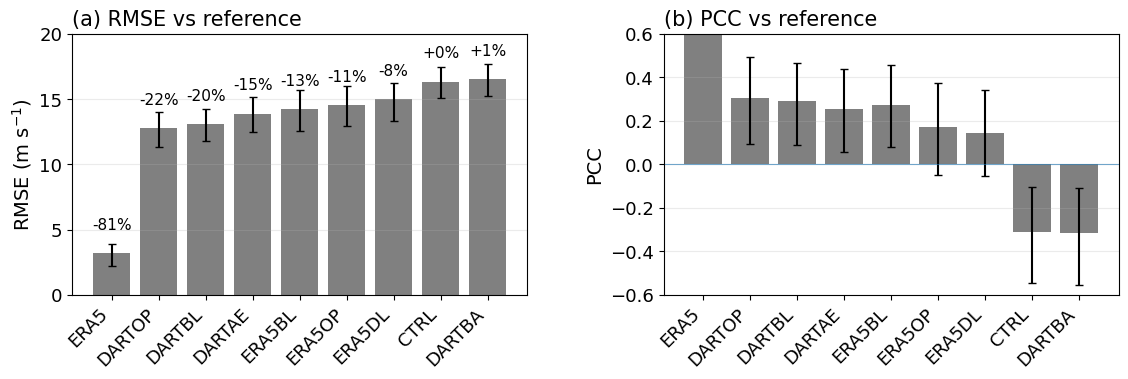

DONE


In [11]:
if __name__ == "__main__":
    work_dir = "/lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper"
    qbo_dir = Path(work_dir) / "figure_data" / "qbo"

    period = "2012-2013"
    ref_exp = "ERAI"
    exp_list = ["ERA5", "CTRL", "DARTOP", "ERA5OP", "ERA5DL", "ERA5BL", "DARTBL", "DARTBA", "DARTAE"] 

    out_dir = Path(work_dir) / "qbo_analysis"
    out_dir.mkdir(parents=True, exist_ok=True)

    parameter = QboPlotParameter(
        main_title="QBO zonal wind (5°S–5°N)",
        test_yrs=period,
        ref_yrs=f"{ref_exp} ({period})",
    )
    plotter = QboPlotter(parameter)

    # Skill bar summary only
    plotter.plot_skill_bar_summary(
        qbo_dir=qbo_dir,
        period=period,
        ref_exp=ref_exp,
        exp_list=exp_list,
        amplitude_method="rms",
        output_dir=out_dir,
        font_scale=14,
        figsize=(11.5, 4.5),
        dpi=300,
        sort_by="rmse",   # "input" | "rmse" | "pcc"
        show=True,
        skip_bad=True,
        ymin1 = 0, 
        ymax1 = 20,
        ymin2 = -0.6, 
        ymax2 = 0.6
    )

    print("DONE")
